## 0. Setup

In [1]:
# Instala MLflow y Optuna para registrar y comparar corridas.
%pip install -q mlflow optuna tensorboard


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Prepara las librerías, el dispositivo y las semillas.
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna
SEEDS = [3, 9, 27]
#Se dejan multiple semillas para futuras simulaciones y para comprobar.

# Elegir manualmente: 0 → 3, 1 → 9, 2 → 27.
SEED_SELECTOR = 1
SEED = SEEDS[SEED_SELECTOR]

# Mantiene las mismas particiones entre experimentos.
SPLIT_SEED = 42


def set_seed(seed):
    """Reinicia las fuentes de aleatoriedad del entrenamiento."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print("Semillas disponibles:", SEEDS)
print("Semilla de entrenamiento seleccionada:", SEED)
print("Semilla de partición:", SPLIT_SEED)
print("Dispositivo:", device)

C:\Users\franc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Semillas disponibles: [3, 9, 27]
Semilla de entrenamiento seleccionada: 9
Semilla de partición: 42
Dispositivo: xpu


In [3]:
# Descarga los recursos de NLTK usados al tokenizar y lematizar.
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups

In [4]:
# Separa train y dev sin repartir copias del mismo texto entre ambos.
import hashlib

newsgroups_train = fetch_20newsgroups(
    subset="train", remove=("headers", "footers", "quotes"),
)
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)


def document_key(text):
    return " ".join(text.lower().split())


document_keys = [document_key(text) for text in newsgroups_train.data]
groups = [f"text:{key}" if key else f"empty:{i}" for i, key in enumerate(document_keys)]
known_document_keys = {key for key in document_keys if key}
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
train_indices, dev_indices = next(
    splitter.split(np.arange(len(groups)), newsgroups_train.target, groups)
)
assert set(np.asarray(groups, dtype=object)[train_indices]).isdisjoint(
    np.asarray(groups, dtype=object)[dev_indices]
)
data_digest = hashlib.sha256()
for text in newsgroups_train.data:
    data_digest.update(hashlib.sha256(text.encode("utf-8")).digest())
for indices in (train_indices, dev_indices):
    data_digest.update(np.asarray(indices, dtype="<i8").tobytes())
DATA_SPLIT_ID = data_digest.hexdigest()

train_texts_raw = [newsgroups_train.data[i] for i in train_indices]
dev_texts_raw = [newsgroups_train.data[i] for i in dev_indices]
y_train = newsgroups_train.target[train_indices]
y_dev = newsgroups_train.target[dev_indices]
print(f"Train: {len(y_train)} | Dev: {len(y_dev)}")

Train: 9052 | Dev: 2262


## 2. Preprocesamiento

In [5]:
# Limpia y lematiza cada documento antes de vectorizarlo.
STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in STOP_WORDS]
    tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)

## 3. Vectorización TF-IDF

In [6]:
# Ajusta TF-IDF con train y aplica el mismo vocabulario al segundo conjunto.
def vectorize_data(train_texts, other_texts, ngram_range, max_features, min_df):
    """Ajusta TF-IDF con train y transforma el segundo conjunto (dev en la búsqueda).

    Los textos deben estar preprocesados. Los hiperparámetros se eligen
    fuera de este wrapper, en el código de cada experimento.
    """
    my_vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df
    )
    X_train = my_vectorizer.fit_transform(train_texts)
    X_other =  my_vectorizer.transform(other_texts)
    return X_train, X_other, my_vectorizer

# Conservamos la normalización L2 por documento que aplica TF-IDF.
# No agregamos estandarización z-score.

## 4. Modelo MLP

In [7]:
# Construye la MLP a partir de los tamaños y la activación elegidos.
class my_MLP_model(nn.Module):
    def __init__(
        self,
        input_dim,
        num_classes,
        hidden_units,
        activation_name,
        batchnorm=False,
        dropout=0.0,
    ):
        super().__init__()

        hidden_units = list(hidden_units)

        if not 1 <= len(hidden_units) <= 3:
            raise ValueError("El modelo debe tener entre 1 y 3 capas ocultas.")

        if any(neurons <= 0 for neurons in hidden_units):
            raise ValueError("La cantidad de neuronas debe ser positiva.")

        if not 0.0 <= dropout < 1.0:
            raise ValueError("dropout debe estar entre 0 inclusive y 1 exclusivo.")

        activations = {
            "sigmoid": nn.Sigmoid,
            "tanh": nn.Tanh,
            "relu": nn.ReLU,
            "elu": nn.ELU,
            "leaky_relu": lambda: nn.LeakyReLU(negative_slope=0.1),
        }

        activation_name = activation_name.lower()

        if activation_name not in activations:
            raise ValueError(f"Activación desconocida: {activation_name}")

        layers = []
        previous_dim = input_dim

        for neurons in hidden_units:
            layers.append(
                nn.Linear(previous_dim, neurons, bias=not batchnorm)
            )

            if batchnorm:
                layers.append(nn.BatchNorm1d(neurons))

            layers.append(activations[activation_name]())

            if dropout > 0:
                layers.append(nn.Dropout(p=dropout))

            previous_dim = neurons

        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

        # Reemplazamos la inicialización predeterminada de las capas.
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

            elif isinstance(layer, nn.BatchNorm1d):
                nn.init.ones_(layer.weight)   # Gamma.
                nn.init.zeros_(layer.bias)   # Beta.

    def forward(self, x):
        return self.network(x)

## 5. Entrenamiento

In [8]:
# Fija los valores de referencia para las próximas corridas.
MAX_EPOCHS = 40  # cambiar manualmente
EARLY_STOPPING_PATIENCE = 15  # fijo; no se optimiza con Optuna
BATCH_SIZES = [64, 128, 256]
ACTIVATION = "leaky_relu"
BASELINE_HIDDEN_UNITS = [256]
BASELINE_BATCH_SIZE = 128
BASELINE_LR = 0.0024524713668806378

### Función de costo J

In [9]:
# Calcula la entropía cruzada y las penalizaciones de J.
def classification_cost(logits, targets, reduction="mean"):
    """Wrapper de entropía cruzada: recibe logits y etiquetas de clase."""
    criterion = nn.CrossEntropyLoss(reduction=reduction)
    return criterion(logits, targets)


def regularization_cost(model, l1_lambda=0.0, l2_lambda=0.0):
    """Devuelve las contribuciones L1 y L2 de los pesos de capas lineales."""
    if l1_lambda < 0 or l2_lambda < 0:
        raise ValueError("Los coeficientes de regularización no pueden ser negativos.")

    reference = next(model.parameters())
    J_l1 = reference.new_zeros(())
    J_l2 = reference.new_zeros(())

    if l1_lambda or l2_lambda:
        for layer in model.modules():
            if isinstance(layer, nn.Linear):
                if l1_lambda:
                    J_l1 = J_l1 + l1_lambda * layer.weight.abs().sum()
                if l2_lambda:
                    J_l2 = J_l2 + l2_lambda * layer.weight.square().sum()

    return J_l1, J_l2


def J(logits, targets, model, l1_lambda=0.0, l2_lambda=0.0):
    """Costo de entrenamiento y sus componentes, conservando sus gradientes."""
    J_ce = classification_cost(logits, targets)
    J_l1, J_l2 = regularization_cost(model, l1_lambda, l2_lambda)
    J_total = J_ce + J_l1 + J_l2
    return J_total, J_ce, J_l1, J_l2


In [10]:
# Prepara los batches, el optimizador y las métricas de evaluación.
import time
from scipy import sparse


def to_tensor_dataset(X, y):
    # Convertimos a float32 antes de densificar para reducir la memoria necesaria.
    if sparse.issparse(X):
        X = X.astype(np.float32).toarray()
    X = torch.as_tensor(np.asarray(X), dtype=torch.float32)
    y = torch.as_tensor(np.asarray(y), dtype=torch.long)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
        raise ValueError("Se esperan características 2D y etiquetas 1D alineadas y no vacías.")
    return TensorDataset(X, y)


def make_loaders(train_dataset, dev_dataset, batch_size, seed, batchnorm=False):
    if batch_size < 1 or (batchnorm and (batch_size < 2 or len(train_dataset) < 2)):
        raise ValueError("BatchNorm necesita al menos dos ejemplos por batch de entrenamiento.")
    generator = torch.Generator().manual_seed(seed)
    # BatchNorm no puede entrenarse con un último batch de un solo ejemplo.
    drop_last = batchnorm and len(train_dataset) % batch_size == 1
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              generator=generator, drop_last=drop_last)
    train_eval_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False,
                                  generator=torch.Generator().manual_seed(seed + 1))
    dev_loader = DataLoader(dev_dataset, batch_size=batch_size, shuffle=False,
                           generator=torch.Generator().manual_seed(seed + 2))
    return train_loader, train_eval_loader, dev_loader


def create_optimizer(model, optimizer_name, lr, **parameters):
    optimizers = {"adam": optim.Adam, "rmsprop": optim.RMSprop, "sgd": optim.SGD}
    name = optimizer_name.lower()
    if name not in optimizers:
        raise ValueError(f"Optimizador desconocido: {optimizer_name}")
    # L2 se agrega explícitamente a la pérdida; evitamos penalizarla dos veces.
    if parameters.get("weight_decay", 0) != 0:
        raise ValueError("Usar weight_decay=0; la regularización L2 se configura en train_mlp_model.")
    if name == "adam" and next(model.parameters()).device.type == "xpu":
        # La actualización agrupada de Adam falla en esta GPU Intel.
        parameters.setdefault("foreach", False)
    return optimizers[name](model.parameters(), lr=lr, **parameters)


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    model_device = next(model.parameters()).device
    loss_sum, correct, count = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(model_device), yb.to(model_device)
        logits = model(xb)
        loss_sum += classification_cost(logits, yb, reduction="sum").item()
        correct += (logits.argmax(dim=1) == yb).sum().item()
        count += len(yb)
    if count == 0:
        raise ValueError("El conjunto de evaluación está vacío.")
    return loss_sum / count, correct / count


@torch.no_grad()
def weight_statistics(model):
    statistics = {}
    for name, layer in model.named_modules():
        if isinstance(layer, nn.Linear):
            weights = layer.weight.abs()
            statistics[name] = {"mean_abs": weights.mean().item(),
                                "max_abs": weights.max().item()}
    return statistics




In [11]:
# Entrena por batches y selecciona el mejor estado según dev.
def train_mlp_model(
    model, train_loader, train_eval_loader, dev_loader, optimizer, epochs=MAX_EPOCHS,
    l1_lambda=0.0, l2_lambda=0.0, writer=None, log_mlflow=False,
    scheduler=None, monitor="val_acc", patience=EARLY_STOPPING_PATIENCE,
    restore_best=True, run_name="mlp", verbose=True,
    batch_callback=None, epoch_callback=None, last_epoch_callback=None,
):
    if epochs < 1 or min(l1_lambda, l2_lambda) < 0:
        raise ValueError("Las épocas deben ser positivas y las penalizaciones no negativas.")
    if monitor not in ("val_acc", "val_loss"):
        raise ValueError("monitor debe ser val_acc o val_loss.")
    if patience is not None and patience < 1:
        raise ValueError("patience debe ser positivo o None.")
    if any(group.get("weight_decay", 0) != 0 for group in optimizer.param_groups):
        raise ValueError("Usar weight_decay=0 para controlar L2 explícitamente.")
    if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
        expected_mode = "max" if monitor == "val_acc" else "min"
        if scheduler.mode != expected_mode:
            raise ValueError("El modo del scheduler no coincide con monitor.")
    if log_mlflow and mlflow.active_run() is None:
        raise ValueError("Abrir un run de MLflow antes de registrar el entrenamiento.")

    # Mover el modelo antes de construir el optimizador, especialmente al usar GPU.
    model_device = next(model.parameters()).device
    linear_weights = [layer.weight for layer in model.modules()
                      if isinstance(layer, nn.Linear)]
    if not linear_weights or len(train_loader) == 0:
        raise ValueError("Se requieren capas lineales y batches de entrenamiento.")

    keys = ["train_loss", "train_acc", "val_loss", "val_acc", "gap_acc",
            "train_batch_loss", "train_batch_acc", "train_objective",
            "train_seconds", "eval_seconds", "epoch_seconds", "lr",
            "l1_penalty", "l2_penalty"]
    history = {key: [] for key in keys}
    history["max_epochs"] = epochs
    history["patience"] = patience
    history["weights"] = []
    history["initial_weights"] = weight_statistics(model)
    best_value, best_state, best_epoch, without_improvement = None, None, 0, 0
    if writer is not None:
        for name, layer in model.named_modules():
            if isinstance(layer, nn.Linear):
                writer.add_histogram(f"weights_abs/{name}", layer.weight.detach().abs().cpu(), 0)

    def synchronize():
        if model_device.type == "cuda":
            torch.cuda.synchronize(model_device)
        elif model_device.type == "xpu":
            torch.xpu.synchronize(model_device)

    synchronize()
    total_start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        lr = optimizer.param_groups[0]["lr"]
        synchronize()
        epoch_start = time.perf_counter()
        loss_sum, objective_sum, correct, count = 0.0, 0.0, 0, 0

        for batch_number, (xb, yb) in enumerate(train_loader, start=1):
            xb, yb = xb.to(model_device), yb.to(model_device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            J_total, J_ce, _, _ = J(
                logits, yb, model, l1_lambda=l1_lambda, l2_lambda=l2_lambda,
            )
            if not torch.isfinite(J_total):
                raise FloatingPointError("Costo no finito; revisar learning rate y regularización.")
            J_total.backward()
            batch_lr = optimizer.param_groups[0]["lr"]
            optimizer.step()
            if isinstance(scheduler, optim.lr_scheduler.CyclicLR):
                scheduler.step()
            n = len(yb)
            loss_sum += J_ce.item() * n
            objective_sum += J_total.item() * n
            correct += (logits.argmax(dim=1) == yb).sum().item()
            count += n
            if batch_callback is not None:
                batch_callback(epoch + 1, batch_number, {
                    "examples": n, "J_ce": J_ce.item(), "J_total": J_total.item(),
                    "accuracy": (logits.argmax(dim=1) == yb).float().mean().item(),
                    "lr": batch_lr,
                })

        synchronize()
        train_seconds = time.perf_counter() - epoch_start
        eval_start = time.perf_counter()
        train_loss, train_acc = evaluate_model(model, train_eval_loader)
        val_loss, val_acc = evaluate_model(model, dev_loader)
        if not np.isfinite([train_loss, val_loss]).all():
            raise FloatingPointError("Pérdida de evaluación no finita.")
        synchronize()
        eval_seconds = time.perf_counter() - eval_start
        with torch.no_grad():
            J_l1, J_l2 = regularization_cost(model, l1_lambda, l2_lambda)
            l1_penalty, l2_penalty = J_l1.item(), J_l2.item()
        statistics = weight_statistics(model)
        synchronize()
        metrics = dict(train_loss=train_loss, train_acc=train_acc, val_loss=val_loss,
                       val_acc=val_acc, gap_acc=train_acc - val_acc,
                       train_batch_loss=loss_sum / count, train_batch_acc=correct / count,
                       train_objective=objective_sum / count, train_seconds=train_seconds,
                       eval_seconds=eval_seconds, epoch_seconds=time.perf_counter() - epoch_start,
                       lr=lr, l1_penalty=l1_penalty, l2_penalty=l2_penalty)
        for key, value in metrics.items():
            history[key].append(value)
        history["weights"].append(statistics)

        # Guardamos el estado completo porque BatchNorm también usa estadísticas acumuladas.
        value = metrics[monitor]
        improved = best_value is None or (value > best_value if monitor == "val_acc" else value < best_value)
        if improved:
            best_value, best_epoch, without_improvement = value, epoch + 1, 0
            if restore_best:
                best_state = {name: tensor.detach().cpu().clone()
                              for name, tensor in model.state_dict().items()}
        else:
            without_improvement += 1

        if epoch_callback is not None:
            epoch_callback(model, history)

        log_metrics = dict(metrics)
        for name, values in statistics.items():
            for statistic, number in values.items():
                log_metrics[f"weights/{name}/{statistic}"] = number
        if writer is not None:
            for key, number in log_metrics.items():
                writer.add_scalar(key, number, epoch + 1)
            if epoch == 0 or (epoch + 1) % 5 == 0 or epoch + 1 == epochs:
                for name, layer in model.named_modules():
                    if isinstance(layer, nn.Linear):
                        writer.add_histogram(f"weights_abs/{name}", layer.weight.detach().abs().cpu(), epoch + 1)
        if log_mlflow:
            mlflow.log_metrics(log_metrics, step=epoch + 1)
        if verbose:
            print(f"[{run_name}] {epoch + 1}/{epochs} | "
                  f"train loss={train_loss:.4f} acc={train_acc:.4f} | "
                  f"dev loss={val_loss:.4f} acc={val_acc:.4f} | "
                  f"lr={lr:.2g} | entrenamiento={train_seconds:.2f}s")
        if scheduler is not None and not isinstance(scheduler, optim.lr_scheduler.CyclicLR):
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(value)
            else:
                scheduler.step()
        if patience is not None and without_improvement >= patience:
            if verbose:
                print(f"Early stopping: {patience} épocas sin mejora de {monitor}. "
                      f"Mejor época: {best_epoch}.")
            break

    synchronize()
    history["total_seconds"] = time.perf_counter() - total_start
    history["best_epoch"] = best_epoch
    history["best_value"] = best_value
    history["monitor"] = monitor
    history["epochs_completed"] = len(history["val_loss"])
    history["stopped_early"] = history["epochs_completed"] < epochs
    history["stop_reason"] = "early_stopping" if history["stopped_early"] else "max_epochs"
    if last_epoch_callback is not None:
        last_epoch_callback(model)
    if restore_best:
        model.load_state_dict(best_state)
    model.eval()
    history["returned_epoch"] = best_epoch if restore_best else history["epochs_completed"]
    history["train_seconds_to_best"] = sum(history["train_seconds"][:best_epoch])
    history["returned_weights"] = weight_statistics(model)
    if writer is not None:
        writer.flush()
    if log_mlflow:
        mlflow.log_metrics({"best_epoch": best_epoch, "best_value": best_value,
                            "total_seconds": history["total_seconds"]})
    return history

## 6. Modelo sin regularización: my_baseline

In [12]:
# my_baseline: configura la corrida y prepara train y dev.
from datetime import datetime
from pathlib import Path
import csv
import hashlib
import json
import platform
import os
import joblib
import nltk
import sklearn

my_baseline_config = {
    "experiment": "my_baseline", "seed": SEED, "split_seed": SPLIT_SEED, "split_id": DATA_SPLIT_ID,
    "hidden_units": BASELINE_HIDDEN_UNITS, "activation": ACTIVATION, "initialization": "xavier_uniform",
    "optimizer": "Adam", "lr": BASELINE_LR,
    "beta1": 0.9, "beta2": 0.999, "batch_size": BASELINE_BATCH_SIZE,
    "max_epochs": MAX_EPOCHS, "patience": None,
    "remove_stopwords": True, "text_normalization": "lemmatize",
    "ngram_range": [1, 1], "max_features": 5000, "min_df": 1,
    "tfidf_norm": "l2", "z_score": False, "dtype": "float32",
    "l1_lambda": 0.0, "l2_lambda": 0.0, "dropout": 0.0,
    "batchnorm": False, "weight_decay": 0.0, "scheduler": None,
}

my_project_dir = Path.cwd()
if not (my_project_dir / "TP_Regularización_seed_9.ipynb").exists():
    my_project_dir = my_project_dir / "TP RN Regularización Bonacina"
if not (my_project_dir / "TP_Regularización_seed_9.ipynb").exists():
    raise FileNotFoundError("No se encontró el notebook del TP en el directorio de trabajo.")

my_run_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
my_run_dir = my_project_dir / ".experimentos" / "my_baseline" / my_run_label
my_run_dir.mkdir(parents=True, exist_ok=False)
torch.set_num_threads(min(4, os.cpu_count() or 1))
my_preparation_start = time.perf_counter()
my_pipeline_start = my_preparation_start

# Se conserva el código de las funciones utilizadas, sin sus salidas.
my_source_notebook = json.loads((my_project_dir / "TP_Regularización_seed_9.ipynb").read_text(encoding="utf-8"))
my_source_code = "\n\n".join(
    "".join(cell.get("source", [])) for cell in my_source_notebook["cells"]
    if cell["cell_type"] == "code" and not "".join(cell.get("source", [])).startswith(("%", "!"))
)
(my_run_dir / "source_snapshot.py").write_text(my_source_code, encoding="utf-8")
my_baseline_config["source_sha256"] = hashlib.sha256(my_source_code.encode()).hexdigest()
my_baseline_config["device"] = str(device)
my_baseline_config["torch_version"] = str(torch.__version__)
my_baseline_config["sklearn_version"] = sklearn.__version__
my_baseline_config["python_version"] = platform.python_version()
my_baseline_config["cpu_threads"] = torch.get_num_threads()

print("Preparando train y dev; el test queda reservado.", flush=True)
# Ajustamos el vectorizador solo con train para mantener dev fuera del ajuste.
my_text_train = [preprocess_text(text) for text in train_texts_raw]
my_text_dev = [preprocess_text(text) for text in dev_texts_raw]
my_X_train, my_X_dev, my_vectorizer = vectorize_data(
    my_text_train, my_text_dev, ngram_range=(1, 1), max_features=5000, min_df=1,
)
my_train_dataset = to_tensor_dataset(my_X_train, y_train)
my_dev_dataset = to_tensor_dataset(my_X_dev, y_dev)
my_train_loader, my_train_eval_loader, my_dev_loader = make_loaders(
    my_train_dataset, my_dev_dataset, batch_size=BASELINE_BATCH_SIZE, seed=SEED,
)
np.savez_compressed(my_run_dir / "split_indices.npz", train=train_indices, dev=dev_indices)
joblib.dump(my_vectorizer, my_run_dir / "vectorizer.joblib")
# Contamos textos vacíos y filas que quedaron sin términos del vocabulario.
my_quality = {}
for name, texts, matrix in [("train", my_text_train, my_X_train), ("dev", my_text_dev, my_X_dev)]:
    lengths = np.array([len(text.split()) for text in texts])
    my_quality[name] = {
        "documents": len(texts), "empty_texts": int((lengths == 0).sum()),
        "zero_vectors": int((matrix.getnnz(axis=1) == 0).sum()),
        "median_words": float(np.median(lengths)), "max_words": int(lengths.max()),
    }
my_baseline_config["input_dim"] = my_X_train.shape[1]
my_baseline_config["num_classes"] = NUM_CLASSES
my_baseline_config["train_documents"] = len(y_train)
my_baseline_config["dev_documents"] = len(y_dev)
my_quality["majority_class"] = int(np.bincount(y_train).argmax())
my_quality["majority_dev_accuracy"] = float(np.mean(y_dev == my_quality["majority_class"]))

set_seed(SEED)
my_model = my_MLP_model(
    input_dim=my_X_train.shape[1], num_classes=NUM_CLASSES,
    hidden_units=BASELINE_HIDDEN_UNITS, activation_name=ACTIVATION,
).to(device)
my_optimizer = create_optimizer(
    my_model, "Adam", lr=my_baseline_config["lr"], betas=(0.9, 0.999), weight_decay=0,
)
my_initial_weights = {name: layer.weight.detach().cpu().clone()
                      for name, layer in my_model.named_modules() if isinstance(layer, nn.Linear)}
torch.save(my_initial_weights, my_run_dir / "initial_weights.pt")
my_baseline_config["parameter_count"] = sum(p.numel() for p in my_model.parameters())
my_baseline_config["preparation_seconds"] = time.perf_counter() - my_preparation_start
(my_run_dir / "config.json").write_text(json.dumps(my_baseline_config, indent=2), encoding="utf-8")
(my_run_dir / "data_quality.json").write_text(json.dumps(my_quality, indent=2), encoding="utf-8")
print(json.dumps(my_baseline_config, indent=2), flush=True)

Preparando train y dev; el test queda reservado.
{
  "experiment": "my_baseline",
  "seed": 9,
  "split_seed": 42,
  "split_id": "beab1f165980d89e7622eb65778b564b2bca78341859fa84639444244c4edc07",
  "hidden_units": [
    256
  ],
  "activation": "leaky_relu",
  "initialization": "xavier_uniform",
  "optimizer": "Adam",
  "lr": 0.0024524713668806378,
  "beta1": 0.9,
  "beta2": 0.999,
  "batch_size": 128,
  "max_epochs": 40,
  "patience": null,
  "remove_stopwords": true,
  "text_normalization": "lemmatize",
  "ngram_range": [
    1,
    1
  ],
  "max_features": 5000,
  "min_df": 1,
  "tfidf_norm": "l2",
  "z_score": false,
  "dtype": "float32",
  "l1_lambda": 0.0,
  "l2_lambda": 0.0,
  "dropout": 0.0,
  "batchnorm": false,
  "weight_decay": 0.0,
  "scheduler": null,
  "source_sha256": "3f3b0735a325fc584381fbc13381497975ea2d7c0380b394fb80188c1962f8b4",
  "device": "xpu",
  "torch_version": "2.14.1+xpu",
  "sklearn_version": "1.9.1",
  "python_version": "3.14.5",
  "cpu_threads": 4,
  "in

In [13]:
# my_baseline: entrena y guarda métricas y estados del modelo.
my_tracking_uri = "sqlite:///" + (my_project_dir / ".experimentos" / "mlflow.db").as_posix()
mlflow.set_tracking_uri(my_tracking_uri)
my_client = mlflow.tracking.MlflowClient()
my_experiment = my_client.get_experiment_by_name("my_baseline")
if my_experiment is None:
    my_experiment_id = my_client.create_experiment(
        "my_baseline", artifact_location=(my_project_dir / ".experimentos" / "mlflow_artifacts").as_uri(),
    )
else:
    my_experiment_id = my_experiment.experiment_id
my_tb_dir = my_project_dir / ".experimentos" / "tensorboard" / "my_baseline" / my_run_label
my_writer = SummaryWriter(log_dir=str(my_tb_dir))
my_baseline_config["tensorboard_dir"] = str(my_tb_dir)

my_batch_file = (my_run_dir / "batches.csv").open("w", newline="", encoding="utf-8")
my_batch_fields = ["step", "epoch", "batch", "examples", "J_ce", "J_total", "accuracy", "lr"]
my_batch_csv = csv.DictWriter(my_batch_file, fieldnames=my_batch_fields)
my_batch_csv.writeheader()
my_step = 0

# El promedio por época esconde cuánto cambian las métricas entre batches.
def my_record_batch(epoch, batch, values):
    global my_step
    my_step += 1
    my_batch_csv.writerow({"step": my_step, "epoch": epoch, "batch": batch, **values})
    my_writer.add_scalar("batches/J_ce", values["J_ce"], my_step)
    my_writer.add_scalar("batches/accuracy", values["accuracy"], my_step)

def my_record_epoch(model, history):
    epoch = len(history["val_acc"])
    my_batch_file.flush()
    progress = {"epoch": epoch, "max_epochs": my_baseline_config["max_epochs"],
                "train_acc": history["train_acc"][-1], "val_acc": history["val_acc"][-1],
                "train_loss": history["train_loss"][-1], "val_loss": history["val_loss"][-1],
                "train_seconds": history["train_seconds"][-1]}
    (my_run_dir / "progress.json").write_text(json.dumps(progress), encoding="utf-8")
    (my_run_dir / "history_partial.json").write_text(json.dumps(history), encoding="utf-8")
    # Guardamos la última época antes de que el entrenador recupere la mejor.
    if epoch == my_baseline_config["max_epochs"]:
        torch.save({"config": my_baseline_config, "epoch": epoch,
                    "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}},
                   my_run_dir / "model_last.pt")

try:
    with mlflow.start_run(experiment_id=my_experiment_id, run_name="my_baseline") as my_run:
        my_baseline_config["mlflow_run_id"] = my_run.info.run_id
        mlflow.log_params({k: json.dumps(v) if isinstance(v, (list, dict)) else str(v)
                           for k, v in my_baseline_config.items()})
        my_baseline_history = train_mlp_model(
            my_model, my_train_loader, my_train_eval_loader, my_dev_loader,
            my_optimizer, epochs=my_baseline_config["max_epochs"],
            l1_lambda=0.0, l2_lambda=0.0, writer=my_writer, log_mlflow=True,
            scheduler=None, patience=None, restore_best=True,
            monitor="val_acc", run_name="my_baseline",
            batch_callback=my_record_batch, epoch_callback=my_record_epoch,
        )
        torch.save({"config": my_baseline_config, "epoch": my_baseline_history["best_epoch"],
                    "state_dict": {k: v.detach().cpu().clone() for k, v in my_model.state_dict().items()}},
                   my_run_dir / "model_best.pt")
        my_baseline_history["pipeline_seconds_before_export"] = time.perf_counter() - my_pipeline_start
        (my_run_dir / "history.json").write_text(json.dumps(my_baseline_history, indent=2), encoding="utf-8")
        (my_run_dir / "config.json").write_text(json.dumps(my_baseline_config, indent=2), encoding="utf-8")
        my_epoch_rows = []
        for epoch in range(my_baseline_history["epochs_completed"]):
            row = {"epoch": epoch + 1}
            row.update({k: v[epoch] for k, v in my_baseline_history.items()
                        if isinstance(v, list) and len(v) == my_baseline_history["epochs_completed"]
                        and k != "weights"})
            for name, statistics in my_baseline_history["weights"][epoch].items():
                row.update({f"{name}_{stat}": value for stat, value in statistics.items()})
            my_epoch_rows.append(row)
        with (my_run_dir / "epochs.csv").open("w", newline="", encoding="utf-8") as stream:
            table_writer = csv.DictWriter(stream, fieldnames=list(my_epoch_rows[0]))
            table_writer.writeheader(); table_writer.writerows(my_epoch_rows)
        for filename in ["config.json", "data_quality.json", "history.json", "epochs.csv",
                         "batches.csv", "model_best.pt", "model_last.pt", "vectorizer.joblib",
                         "initial_weights.pt", "split_indices.npz", "source_snapshot.py"]:
            if filename == "batches.csv":
                my_batch_file.flush()
            mlflow.log_artifact(str(my_run_dir / filename), artifact_path="my_baseline")
finally:
    my_batch_file.close()
    my_writer.close()

my_manifest = {"run_dir": str(my_run_dir), "config": my_baseline_config,
               "epochs_completed": my_baseline_history["epochs_completed"]}
(my_run_dir.parent / "latest.json").write_text(json.dumps(my_manifest, indent=2), encoding="utf-8")
print("Corrida guardada:", my_run_dir, flush=True)
print("Épocas realizadas:", my_baseline_history["epochs_completed"], flush=True)
print("Tiempo de preparación (s):", round(my_baseline_config["preparation_seconds"], 2), flush=True)
print("Tiempo de entrenamiento y evaluación instrumentados (s):",
      round(my_baseline_history["total_seconds"], 2), flush=True)


[my_baseline] 1/40 | train loss=1.0181 acc=0.8173 | dev loss=1.3112 acc=0.6874 | lr=0.0025 | entrenamiento=0.97s
[my_baseline] 2/40 | train loss=0.4859 acc=0.9025 | dev loss=1.0134 acc=0.7060 | lr=0.0025 | entrenamiento=0.37s
[my_baseline] 3/40 | train loss=0.2863 acc=0.9468 | dev loss=0.9933 acc=0.7025 | lr=0.0025 | entrenamiento=0.35s
[my_baseline] 4/40 | train loss=0.1954 acc=0.9634 | dev loss=1.0169 acc=0.6994 | lr=0.0025 | entrenamiento=0.31s
[my_baseline] 5/40 | train loss=0.1516 acc=0.9679 | dev loss=1.0543 acc=0.6910 | lr=0.0025 | entrenamiento=0.32s
[my_baseline] 6/40 | train loss=0.1304 acc=0.9695 | dev loss=1.0908 acc=0.6936 | lr=0.0025 | entrenamiento=0.27s
[my_baseline] 7/40 | train loss=0.1191 acc=0.9695 | dev loss=1.1279 acc=0.6888 | lr=0.0025 | entrenamiento=0.27s
[my_baseline] 8/40 | train loss=0.1116 acc=0.9696 | dev loss=1.1654 acc=0.6795 | lr=0.0025 | entrenamiento=0.27s
[my_baseline] 9/40 | train loss=0.1072 acc=0.9706 | dev loss=1.1960 acc=0.6835 | lr=0.0025 | ent

## 7. Regularización controlada

Usamos la partición, el vectorizador y los pesos iniciales de `my_baseline`. Cada variante se entrena desde cero con un Adam nuevo, la misma semilla, batch 128, learning rate fijo y un máximo de 40 épocas. Seleccionamos la mejor época por accuracy de dev y comparamos además todas las corridas en la última época.

En cada apartado mostramos curvas de entropía cruzada y accuracy, una tabla con métricas y tiempos, y la distribución de los pesos lineales en la última época. Medimos la variación de la entropía cruzada entre batches al principio y al final. Ejecutá las tres celdas compartidas antes de una subsección. Los barridos completos que coincidan con el baseline se cargan desde disco.

In [14]:
# Sección 7: carga el baseline y prepara una vez los datos para todos los experimentos.

import csv
import json
import time
from datetime import datetime
from pathlib import Path

import joblib
import pandas as pd

my_reg_project = Path.cwd()
if not (my_reg_project / "TP_Regularización_seed_9.ipynb").is_file():
    my_reg_project = my_reg_project / "TP RN Regularización Bonacina"

my_reg_root = my_reg_project / ".experimentos"
my_reg_manifest = my_reg_root / "my_baseline" / "latest.json"
if not my_reg_manifest.is_file():
    raise FileNotFoundError("Hace falta una corrida guardada de my_baseline.")

my_reg_reference = json.loads(my_reg_manifest.read_text(encoding="utf-8"))
my_reg_baseline_dir = my_reg_manifest.parent / Path(my_reg_reference["run_dir"]).name
my_reg_config = json.loads((my_reg_baseline_dir / "config.json").read_text(encoding="utf-8"))
my_reg_baseline_history = json.loads(
    (my_reg_baseline_dir / "history.json").read_text(encoding="utf-8")
)
if (my_reg_config.get("split_id") != DATA_SPLIT_ID
    or my_reg_config["activation"] != ACTIVATION
    or my_reg_config["seed"] != SEED
    or my_reg_config["batch_size"] != BASELINE_BATCH_SIZE
    or my_reg_config["hidden_units"] != BASELINE_HIDDEN_UNITS
    or my_reg_config["lr"] != BASELINE_LR
    or my_reg_config["device"] != str(device)
    or my_reg_config["patience"] is not None
    or my_reg_baseline_history["epochs_completed"] != MAX_EPOCHS):
    raise ValueError("Volvé a correr la sección 6 para actualizar el baseline.")
my_reg_epochs = my_reg_baseline_history["epochs_completed"]

# Reutilizamos el vectorizador y los índices guardados con la referencia.
my_reg_prep_start = time.perf_counter()
my_reg_vectorizer = joblib.load(my_reg_baseline_dir / "vectorizer.joblib")
with np.load(my_reg_baseline_dir / "split_indices.npz") as indices:
    my_reg_train_indices, my_reg_dev_indices = indices["train"], indices["dev"]

assert len(my_reg_train_indices) == my_reg_config["train_documents"]
assert len(my_reg_dev_indices) == my_reg_config["dev_documents"]
assert np.array_equal(my_reg_train_indices, train_indices)
assert np.array_equal(my_reg_dev_indices, dev_indices)
my_reg_datasets = []
for indices in (my_reg_train_indices, my_reg_dev_indices):
    texts = [preprocess_text(newsgroups_train.data[i]) for i in indices]
    features = my_reg_vectorizer.transform(texts)
    my_reg_datasets.append(to_tensor_dataset(features, newsgroups_train.target[indices]))

my_reg_initial = torch.load(
    my_reg_baseline_dir / "initial_weights.pt", map_location="cpu", weights_only=True
)
my_reg_device = torch.device(my_reg_config["device"])
torch.set_num_threads(my_reg_config["cpu_threads"])
my_reg_preparation_seconds = time.perf_counter() - my_reg_prep_start
print(f"Preparación compartida: {my_reg_preparation_seconds:.2f} s")

Preparación compartida: 12.75 s


In [15]:
# Regularización: vuelve a entrenar desde el estado inicial del baseline.

def my_run_regularization(experiment, run_dir, experiment_id, name, settings):
    l1, l2 = settings["lambda_l1"], settings["lambda_l2"]
    dropout, batchnorm = settings["dropout"], settings["batchnorm"]
    patience = settings["patience"]
    folder = run_dir / name
    folder.mkdir()
    set_seed(my_reg_config["seed"])
    loaders = make_loaders(
        *my_reg_datasets, batch_size=my_reg_config["batch_size"], seed=my_reg_config["seed"],
        batchnorm=batchnorm,
    )
    model = my_MLP_model(
        input_dim=my_reg_config["input_dim"],
        num_classes=my_reg_config["num_classes"],
        hidden_units=my_reg_config["hidden_units"],
        activation_name=my_reg_config["activation"],
        dropout=dropout, batchnorm=batchnorm,
    ).to(my_reg_device)

    # BatchNorm y Dropout cambian los índices de Sequential. Emparejamos las capas lineales por orden.
    linears = [(key, layer) for key, layer in model.named_modules() if isinstance(layer, nn.Linear)]
    if len(linears) != len(my_reg_initial):
        raise ValueError("La arquitectura no coincide con las capas del baseline.")
    with torch.no_grad():
        for (_, layer), weight in zip(linears, my_reg_initial.values()):
            layer.weight.copy_(weight)

    optimizer = create_optimizer(
        model, my_reg_config["optimizer"], lr=my_reg_config["lr"],
        betas=(my_reg_config["beta1"], my_reg_config["beta2"]), weight_decay=0,
    )
    params = {
        **settings, "baseline": my_reg_baseline_dir.name,
        "seed": my_reg_config["seed"], "batch_size": my_reg_config["batch_size"],
        "epochs": my_reg_epochs, "activation": my_reg_config["activation"],
        "optimizer": my_reg_config["optimizer"], "lr": my_reg_config["lr"],
        "shared_preparation_seconds": my_reg_preparation_seconds,
    }
    tb_dir = my_reg_root / "tensorboard" / experiment / run_dir.name / name
    fields = ["step", "epoch", "batch", "examples", "J_ce", "J_total", "accuracy", "lr"]

    with SummaryWriter(log_dir=str(tb_dir)) as writer, (
        folder / "batches.csv"
    ).open("w", newline="", encoding="utf-8") as batch_file:
        batch_csv = csv.DictWriter(batch_file, fieldnames=fields)
        batch_csv.writeheader()

        def record_batch(epoch, batch, values):
            step = (epoch - 1) * len(loaders[0]) + batch
            batch_csv.writerow({"step": step, "epoch": epoch, "batch": batch, **values})
            writer.add_scalar("batches/J_ce", values["J_ce"], step)
            writer.add_scalar("batches/accuracy", values["accuracy"], step)

        def record_epoch(current_model, history):
            batch_file.flush()

        def save_last(current_model):
            # Se guarda antes de restaurar los pesos de la mejor época de dev.
            torch.save(current_model.state_dict(), folder / "model_last.pt")

        with mlflow.start_run(experiment_id=experiment_id, run_name=name):
            mlflow.log_params(params)
            history = train_mlp_model(
                model, *loaders, optimizer, epochs=my_reg_epochs, l1_lambda=l1, l2_lambda=l2,
                patience=patience, monitor="val_acc", restore_best=True,
                writer=writer, log_mlflow=True, run_name=name,
                batch_callback=record_batch, epoch_callback=record_epoch,
                last_epoch_callback=save_last,
            )
            torch.save(model.state_dict(), folder / "model_best.pt")
            (folder / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
            (folder / "config.json").write_text(json.dumps(params, indent=2), encoding="utf-8")
            mlflow.log_artifacts(str(folder))

    return {"history": history, "folder": folder, "config": params}

def my_load_regularization(folder, settings):
    required = ("config.json", "history.json", "batches.csv", "model_last.pt", "model_best.pt")
    if not all((folder / name).is_file() for name in required):
        return None
    config = json.loads((folder / "config.json").read_text(encoding="utf-8"))
    history = json.loads((folder / "history.json").read_text(encoding="utf-8"))
    if (config.get("baseline") != my_reg_baseline_dir.name
        or config.get("seed") != my_reg_config["seed"]
        or config.get("batch_size") != my_reg_config["batch_size"]
        or config.get("optimizer") != my_reg_config["optimizer"]
        or config.get("lr") != my_reg_config["lr"]
        or history.get("max_epochs") != my_reg_epochs
        or history.get("patience") != settings["patience"]
        or (history.get("epochs_completed") != my_reg_epochs and not history.get("stopped_early"))
        or any(config.get(key, 0) != value for key, value in settings.items() if key != "patience")):
        return None
    return {"history": history, "folder": folder, "config": {**config, **settings}}


def my_regularization_sweep(experiment, variants):
    root = my_reg_root / experiment
    saved = sorted((p for p in root.glob("*") if p.is_dir()), reverse=True)
    # Si ya existe este barrido con el mismo control, recuperamos sus resultados.
    for run_dir in saved:
        results = {}
        for label, settings in variants.items():
            result = my_load_regularization(run_dir / f"{experiment}_{label}", settings)
            if result is None:
                break
            results[label] = result
        if len(results) == len(variants):
            print(f"Corridas guardadas: {run_dir.name}")
            return run_dir, results

    run_dir = root / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    run_dir.mkdir(parents=True, exist_ok=False)
    mlflow.set_tracking_uri("sqlite:///" + (my_reg_root / "mlflow.db").as_posix())
    client = mlflow.tracking.MlflowClient()
    existing = client.get_experiment_by_name(experiment)
    experiment_id = existing.experiment_id if existing else client.create_experiment(
        experiment, artifact_location=(my_reg_root / f"mlflow_artifacts_{experiment[3:]}").resolve().as_uri()
    )
    results = {
        label: my_run_regularization(
            experiment, run_dir, experiment_id, f"{experiment}_{label}", settings
        )
        for label, settings in variants.items()
    }
    return run_dir, results


def my_reg_settings(l1=0.0, l2=0.0, dropout=0.0, batchnorm=False, patience=None):
    return {
        "lambda_l1": l1, "lambda_l2": l2, "dropout": dropout,
        "batchnorm": batchnorm, "patience": patience,
    }

In [16]:
# Sección 7: muestra las mismas curvas y tablas para todas las técnicas.

def my_compare_regularization(results, run_dir):
    baseline = {
        "history": my_reg_baseline_history, "folder": my_reg_baseline_dir,
        "config": my_reg_settings(),
    }
    runs = {"Baseline": baseline, **results}
    colors = plt.get_cmap("tab10").colors
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    metrics = [
        ("train_loss", "CE de train"), ("val_loss", "CE de dev"),
        ("train_acc", "Accuracy de train"), ("val_acc", "Accuracy de dev"),
    ]
    for ax, (key, title) in zip(axes.flat, metrics):
        marked = False
        for i, (label, result) in enumerate(runs.items()):
            history = result["history"]
            last_epoch = history["epochs_completed"]
            ax.plot(range(1, last_epoch + 1), history[key], label=label,
                    color="black" if i == 0 else colors[i - 1],
                    linestyle="--" if i == 0 else "-")
            if history["stopped_early"]:
                ax.plot(last_epoch, history[key][-1], marker="D", color="red",
                        linestyle="none", zorder=5,
                        label="Early stopping" if not marked else "_nolegend_")
                marked = True
        ax.set(title=title, xlabel="Época", xlim=(0.5, my_reg_epochs + 0.5))
        ax.grid(alpha=0.2)
    axes[0, 1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

    rows, noise_rows = [], []
    for label, result in runs.items():
        h, cfg = result["history"], result["config"]
        for moment, epoch in [("Mejor dev", h["best_epoch"]), ("Última", h["epochs_completed"])]:
            i = epoch - 1
            rows.append({
                "modelo": label, "λ₁": cfg["lambda_l1"], "λ₂": cfg["lambda_l2"],
                "dropout": cfg["dropout"], "BatchNorm": cfg["batchnorm"],
                "momento": moment, "época": epoch, "épocas hechas": h["epochs_completed"],
                "early stopping": h["stopped_early"],
                "accuracy train (%)": 100 * h["train_acc"][i],
                "accuracy dev (%)": 100 * h["val_acc"][i], "CE train": h["train_loss"][i],
                "CE dev": h["val_loss"][i], "brecha (pp)": 100 * h["gap_acc"][i],
                "s acumulados por época": sum(h["epoch_seconds"][:epoch]),
                "s del entrenador": h["total_seconds"],
            })
        batches = pd.read_csv(result["folder"] / "batches.csv")
        # Variación de CE dentro de cada época, medida sobre los batches de entrenamiento.
        spread = batches.groupby("epoch")["J_ce"].std(ddof=0)
        noise_rows.append({
            "modelo": label, "CE por batch · épocas 1–5": spread.loc[1:5].mean(),
            f"CE por batch · últimas {min(5, my_reg_epochs)} épocas": spread.tail(5).mean(),
        })

    weight_rows = []
    fig, axes = plt.subplots(1, len(my_reg_initial), figsize=(12, 4), squeeze=False)
    for i, (label, result) in enumerate(runs.items()):
        checkpoint = torch.load(
            result["folder"] / "model_last.pt", map_location="cpu", weights_only=True
        )
        state = checkpoint.get("state_dict", checkpoint)
        # history contiene solo capas lineales y respeta el orden de la red.
        layer_names = list(result["history"]["weights"][-1])
        for number, (ax, key) in enumerate(zip(axes.flat, layer_names), start=1):
            values = np.sort(state[f"{key}.weight"].abs().numpy().ravel())
            ax.plot(values, np.arange(1, len(values) + 1) / len(values), label=label,
                    color="black" if i == 0 else colors[i - 1],
                    linestyle="--" if i == 0 else "-")
            layer = "Salida" if number == len(layer_names) else f"Oculta {number}"
            weight_rows.append({
                "modelo": label, "capa": layer, "época": result["history"]["epochs_completed"],
                "media |w|": values.mean(),
                "máx. |w|": values.max(), "% con |w| < 0,001": 100 * np.mean(values < 1e-3),
            })
            ax.set(title=layer, xlabel="|w|", ylabel="Fracción acumulada")
    for ax in axes.flat:
        ax.axvline(1e-3, linestyle=":", color="gray", linewidth=1)
        ax.set_xscale("symlog", linthresh=1e-5)
        ax.grid(alpha=0.2)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Distribución de pesos en la última época de cada corrida")
    fig.tight_layout()
    plt.show()

    weights_file = "pesos_ultima_epoca.csv" if any(
        r["history"]["stopped_early"] for r in runs.values()
    ) else f"pesos_epoca{my_reg_epochs}.csv"
    for records, filename in [
        (rows, "comparacion_seccion7.csv"), (weight_rows, weights_file), (noise_rows, "ruido_seccion7.csv"),
    ]:
        table = pd.DataFrame(records)
        display(table.round(5))
        table.to_csv(run_dir / filename, index=False)

### 7.1 Regularización L1

Probamos $\lambda_1=10^{-6},10^{-5},10^{-4}$. Miramos qué proporción de pesos queda cerca de cero y cómo evoluciona la pérdida de dev.


In [17]:
# L1: prueba tres intensidades de L1.

my_l1_lambdas = [1e-6, 1e-5, 1e-4]
my_l1_run_dir, my_l1_runs = my_regularization_sweep(
    "my_l1", {f"{value:.0e}": my_reg_settings(l1=value) for value in my_l1_lambdas}
)


[my_l1_1e-06] 1/40 | train loss=1.0276 acc=0.8167 | dev loss=1.3184 acc=0.6857 | lr=0.0025 | entrenamiento=0.33s
[my_l1_1e-06] 2/40 | train loss=0.4948 acc=0.9010 | dev loss=1.0188 acc=0.7042 | lr=0.0025 | entrenamiento=0.32s
[my_l1_1e-06] 3/40 | train loss=0.2945 acc=0.9461 | dev loss=0.9967 acc=0.7025 | lr=0.0025 | entrenamiento=0.32s
[my_l1_1e-06] 4/40 | train loss=0.2024 acc=0.9632 | dev loss=1.0180 acc=0.6976 | lr=0.0025 | entrenamiento=0.30s
[my_l1_1e-06] 5/40 | train loss=0.1577 acc=0.9674 | dev loss=1.0532 acc=0.6945 | lr=0.0025 | entrenamiento=0.29s
[my_l1_1e-06] 6/40 | train loss=0.1360 acc=0.9695 | dev loss=1.0876 acc=0.6941 | lr=0.0025 | entrenamiento=0.30s
[my_l1_1e-06] 7/40 | train loss=0.1243 acc=0.9694 | dev loss=1.1217 acc=0.6870 | lr=0.0025 | entrenamiento=0.29s
[my_l1_1e-06] 8/40 | train loss=0.1167 acc=0.9696 | dev loss=1.1574 acc=0.6773 | lr=0.0025 | entrenamiento=0.30s
[my_l1_1e-06] 9/40 | train loss=0.1122 acc=0.9707 | dev loss=1.1844 acc=0.6813 | lr=0.0025 | ent

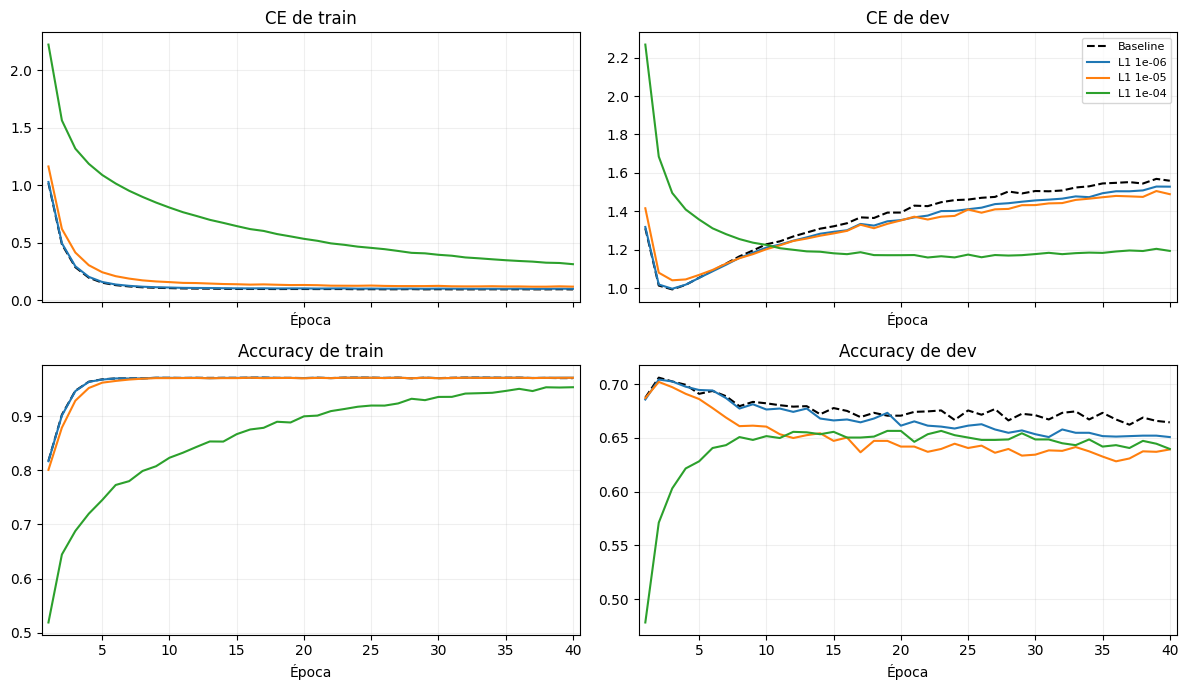

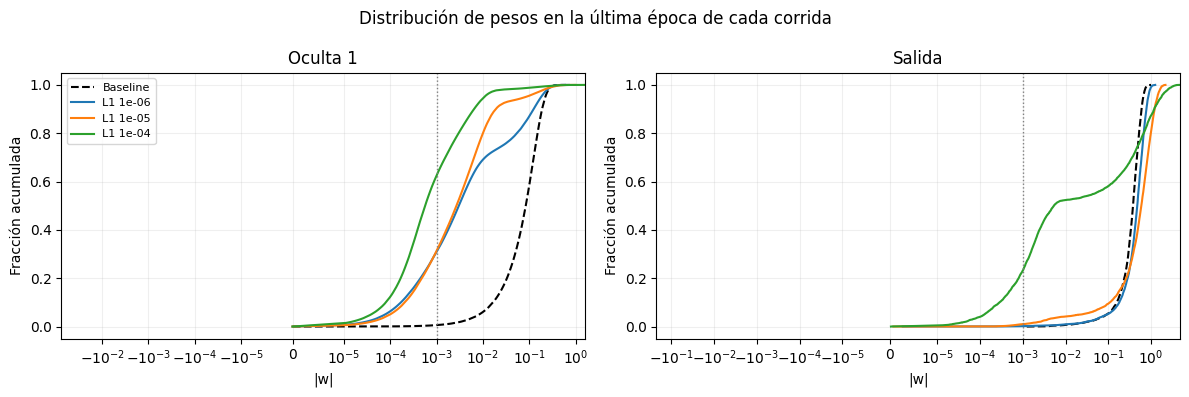

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0.00000,0.0,0.0,False,Mejor dev,2,40,False,90.24525,70.60124,0.48587,1.01337,19.64401,1.60407,17.59974
1,Baseline,0.00000,0.0,0.0,False,Última,40,40,False,97.00619,66.44562,0.09327,1.55916,30.56056,16.67595,17.59974
2,L1 1e-06,0.00000,0.0,0.0,False,Mejor dev,2,40,False,90.10163,70.42440,0.49482,1.01883,19.67723,0.85075,17.90468
3,L1 1e-06,0.00000,0.0,0.0,False,Última,40,40,False,97.08352,65.07515,0.09850,1.52835,32.00836,17.06406,17.90468
4,L1 1e-05,0.00001,0.0,0.0,False,Mejor dev,2,40,False,87.87008,70.20336,0.61923,1.08033,17.66672,0.90890,17.90678
5,L1 1e-05,0.00001,0.0,0.0,False,Última,40,40,False,97.07247,63.92573,0.11730,1.48916,33.14674,17.05187,17.90678
6,L1 1e-04,0.00010,0.0,0.0,False,Mejor dev,19,40,False,88.82015,65.64987,0.55450,1.17143,23.17028,9.23335,19.66658
7,L1 1e-04,0.00010,0.0,0.0,False,Última,40,40,False,95.32700,63.96994,0.31272,1.19379,31.35706,18.72130,19.66658


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09539,0.62606,0.59602
1,Baseline,Salida,40,0.37909,1.00001,0.00000
2,L1 1e-06,Oculta 1,40,0.03292,0.71466,30.86531
3,L1 1e-06,Salida,40,0.47827,1.25192,0.17578
4,L1 1e-05,Oculta 1,40,0.01569,0.98865,31.34148
5,L1 1e-05,Salida,40,0.63848,2.17500,1.03516
6,L1 1e-04,Oculta 1,40,0.00539,1.52251,62.53648
7,L1 1e-04,Salida,40,0.36316,4.53240,23.22266


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16964,0.04619
1,L1 1e-06,0.16867,0.04656
2,L1 1e-05,0.16555,0.04722
3,L1 1e-04,0.13791,0.06429


In [18]:
# L1: compara las tres intensidades con el baseline.

my_compare_regularization({f"L1 {label}": result for label, result in my_l1_runs.items()}, my_l1_run_dir)


### 7.2 Regularización L2

Probamos $\lambda_2=10^{-5},10^{-4},10^{-3}$. La penalización cuadrática se suma a $J$ y Adam usa `weight_decay=0`.


In [19]:
# L2: prueba tres intensidades de L2.

my_l2_lambdas = [1e-5, 1e-4, 1e-3]
my_l2_run_dir, my_l2_runs = my_regularization_sweep(
    "my_l2", {f"{value:.0e}": my_reg_settings(l2=value) for value in my_l2_lambdas}
)


[my_l2_1e-05] 1/40 | train loss=1.0233 acc=0.8175 | dev loss=1.3156 acc=0.6857 | lr=0.0025 | entrenamiento=0.37s
[my_l2_1e-05] 2/40 | train loss=0.4946 acc=0.9010 | dev loss=1.0199 acc=0.7047 | lr=0.0025 | entrenamiento=0.33s
[my_l2_1e-05] 3/40 | train loss=0.2967 acc=0.9462 | dev loss=0.9992 acc=0.7007 | lr=0.0025 | entrenamiento=0.33s
[my_l2_1e-05] 4/40 | train loss=0.2058 acc=0.9631 | dev loss=1.0206 acc=0.6981 | lr=0.0025 | entrenamiento=0.32s
[my_l2_1e-05] 5/40 | train loss=0.1618 acc=0.9670 | dev loss=1.0551 acc=0.6897 | lr=0.0025 | entrenamiento=0.34s
[my_l2_1e-05] 6/40 | train loss=0.1404 acc=0.9694 | dev loss=1.0880 acc=0.6923 | lr=0.0025 | entrenamiento=0.38s
[my_l2_1e-05] 7/40 | train loss=0.1288 acc=0.9694 | dev loss=1.1195 acc=0.6835 | lr=0.0025 | entrenamiento=0.35s
[my_l2_1e-05] 8/40 | train loss=0.1215 acc=0.9701 | dev loss=1.1531 acc=0.6751 | lr=0.0025 | entrenamiento=0.32s
[my_l2_1e-05] 9/40 | train loss=0.1169 acc=0.9706 | dev loss=1.1767 acc=0.6768 | lr=0.0025 | ent

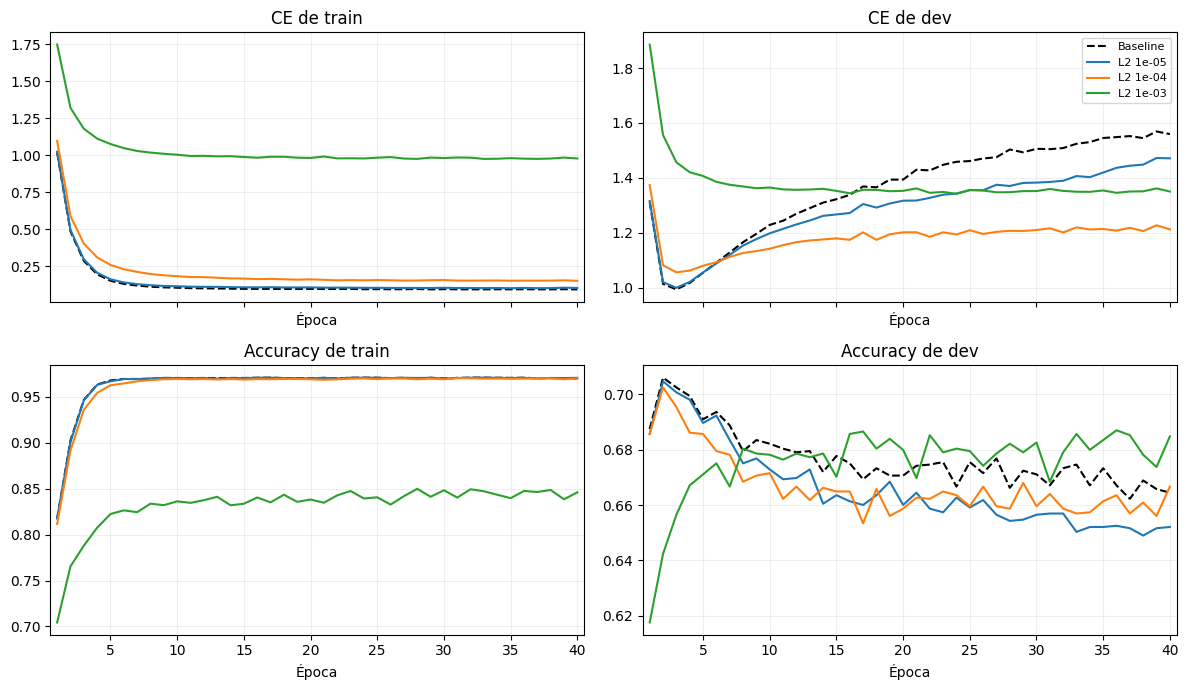

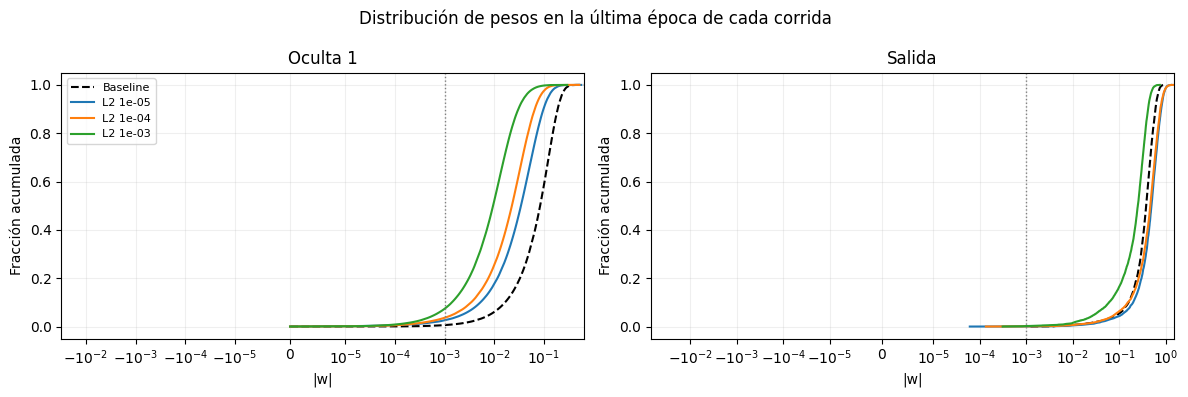

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0.0,0.00000,0.0,False,Mejor dev,2,40,False,90.24525,70.60124,0.48587,1.01337,19.64401,1.60407,17.59974
1,Baseline,0.0,0.00000,0.0,False,Última,40,40,False,97.00619,66.44562,0.09327,1.55916,30.56056,16.67595,17.59974
2,L2 1e-05,0.0,0.00001,0.0,False,Mejor dev,2,40,False,90.10163,70.46861,0.49460,1.01991,19.63302,0.93892,19.51773
3,L2 1e-05,0.0,0.00001,0.0,False,Última,40,40,False,97.07247,65.20778,0.10329,1.47095,31.86469,18.59258,19.51773
4,L2 1e-04,0.0,0.00010,0.0,False,Mejor dev,2,40,False,89.16262,70.24757,0.58792,1.08148,18.91505,1.05541,20.98446
5,L2 1e-04,0.0,0.00010,0.0,False,Última,40,40,False,97.00619,66.66667,0.15121,1.21207,30.33952,20.05792,20.98446
6,L2 1e-03,0.0,0.00100,0.0,False,Mejor dev,36,40,False,84.75475,68.70027,0.97686,1.34526,16.05449,19.58370,22.41572
7,L2 1e-03,0.0,0.00100,0.0,False,Última,40,40,False,84.60009,68.47922,0.97806,1.35006,16.12087,21.46669,22.41572


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09539,0.62606,0.59602
1,Baseline,Salida,40,0.37909,1.00001,0.00000
2,L2 1e-05,Oculta 1,40,0.04485,0.56642,2.56297
3,L2 1e-05,Salida,40,0.49580,1.31180,0.01953
4,L2 1e-04,Oculta 1,40,0.02983,0.51944,3.62398
5,L2 1e-04,Salida,40,0.46648,1.42587,0.07812
6,L2 1e-03,Oculta 1,40,0.01372,0.29646,7.33930
7,L2 1e-03,Salida,40,0.24633,0.74655,0.17578


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16964,0.04619
1,L2 1e-05,0.16878,0.04799
2,L2 1e-04,0.16829,0.05787
3,L2 1e-03,0.14955,0.11295


In [20]:
# L2: compara las tres intensidades con el baseline.

my_compare_regularization({f"L2 {label}": result for label, result in my_l2_runs.items()}, my_l2_run_dir)


### 7.3 Regularización L1 + L2

Fijamos $\lambda_1=10^{-6}$ y usamos las tres intensidades de 7.2. Comparamos cada combinación con L2 al mismo $\lambda_2$.


In [21]:
# L1 + L2: combina L1 fijo con las tres intensidades de L2.

my_l1_l2_run_dir, my_l1_l2_runs = my_regularization_sweep(
    "my_l1_l2", {
        f"{value:.0e}": my_reg_settings(l1=1e-6, l2=value)
        for value in my_l2_lambdas
    }
)


[my_l1_l2_1e-05] 1/40 | train loss=1.0361 acc=0.8160 | dev loss=1.3251 acc=0.6857 | lr=0.0025 | entrenamiento=0.33s
[my_l1_l2_1e-05] 2/40 | train loss=0.5053 acc=0.9001 | dev loss=1.0257 acc=0.7051 | lr=0.0025 | entrenamiento=0.36s
[my_l1_l2_1e-05] 3/40 | train loss=0.3062 acc=0.9453 | dev loss=1.0030 acc=0.7011 | lr=0.0025 | entrenamiento=0.41s
[my_l1_l2_1e-05] 4/40 | train loss=0.2139 acc=0.9625 | dev loss=1.0225 acc=0.6963 | lr=0.0025 | entrenamiento=0.34s
[my_l1_l2_1e-05] 5/40 | train loss=0.1687 acc=0.9670 | dev loss=1.0560 acc=0.6945 | lr=0.0025 | entrenamiento=0.35s
[my_l1_l2_1e-05] 6/40 | train loss=0.1468 acc=0.9688 | dev loss=1.0881 acc=0.6892 | lr=0.0025 | entrenamiento=0.39s
[my_l1_l2_1e-05] 7/40 | train loss=0.1347 acc=0.9692 | dev loss=1.1186 acc=0.6826 | lr=0.0025 | entrenamiento=0.37s
[my_l1_l2_1e-05] 8/40 | train loss=0.1273 acc=0.9701 | dev loss=1.1517 acc=0.6755 | lr=0.0025 | entrenamiento=0.35s
[my_l1_l2_1e-05] 9/40 | train loss=0.1225 acc=0.9706 | dev loss=1.1741 a

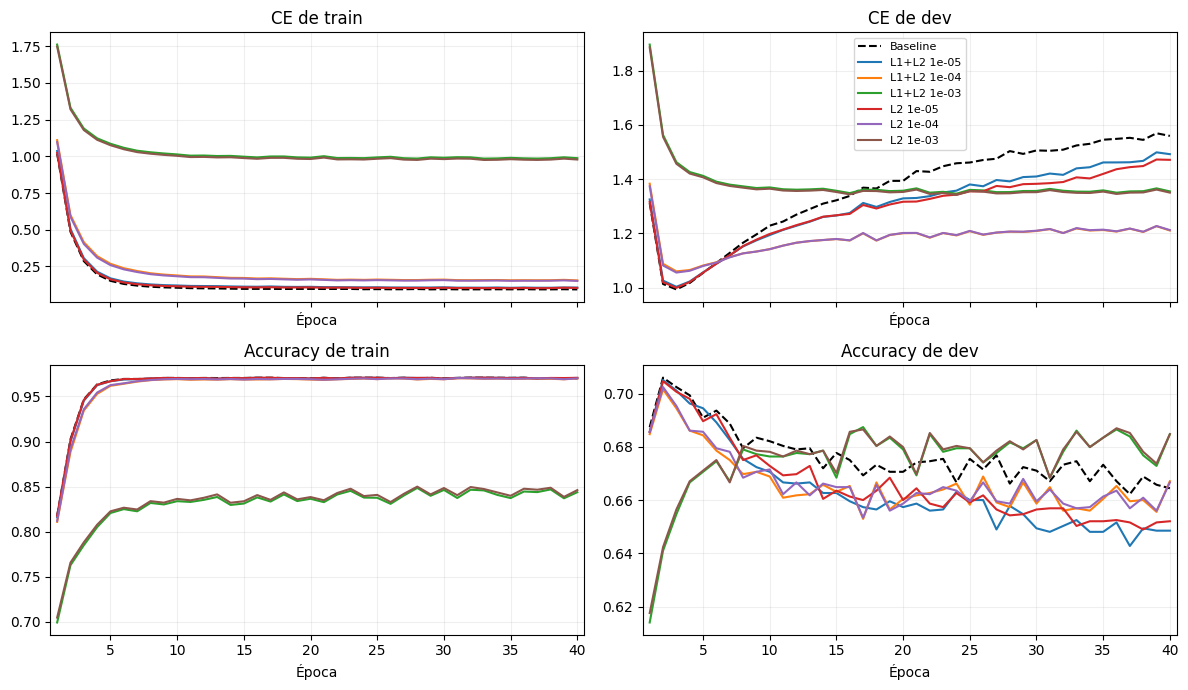

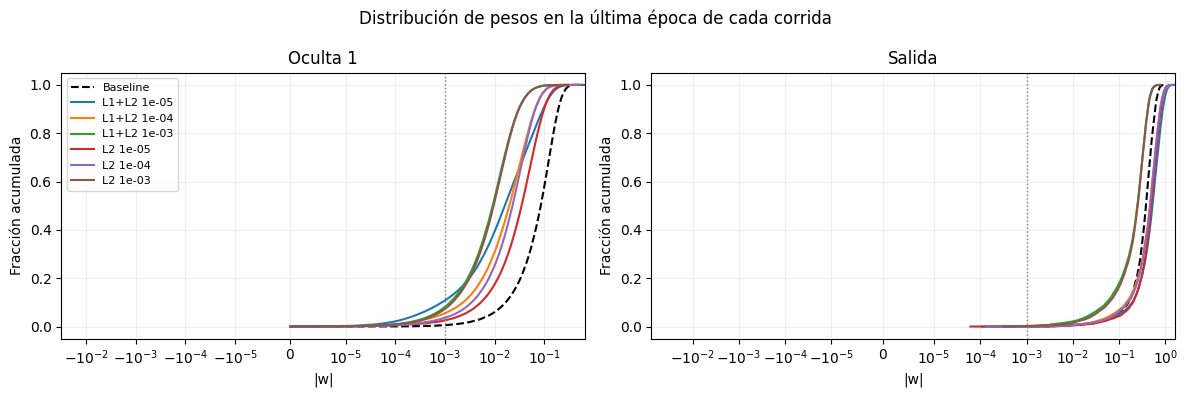

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0.0,0.00000,0.0,False,Mejor dev,2,40,False,90.24525,70.60124,0.48587,1.01337,19.64401,1.60407,17.59974
1,Baseline,0.0,0.00000,0.0,False,Última,40,40,False,97.00619,66.44562,0.09327,1.55916,30.56056,16.67595,17.59974
2,L1+L2 1e-05,0.0,0.00001,0.0,False,Mejor dev,2,40,False,90.01326,70.51282,0.50527,1.02569,19.50044,0.90101,21.10694
3,L1+L2 1e-05,0.0,0.00001,0.0,False,Última,40,40,False,97.06142,64.85411,0.10578,1.49183,32.20731,20.14691,21.10694
4,L1+L2 1e-04,0.0,0.00010,0.0,False,Mejor dev,2,40,False,88.83120,70.15915,0.60004,1.08768,18.67205,0.97979,21.24389
5,L1+L2 1e-04,0.0,0.00010,0.0,False,Última,40,40,False,97.00619,66.71088,0.15460,1.21044,30.29531,20.32020,21.24389
6,L1+L2 1e-03,0.0,0.00100,0.0,False,Mejor dev,17,40,False,83.32965,68.74447,0.99886,1.36103,14.58518,9.17901,22.24968
7,L1+L2 1e-03,0.0,0.00100,0.0,False,Última,40,40,False,84.36810,68.47922,0.98736,1.35468,15.88887,21.25337,22.24968
8,L2 1e-05,0.0,0.00001,0.0,False,Mejor dev,2,40,False,90.10163,70.46861,0.49460,1.01991,19.63302,0.93892,19.51773
9,L2 1e-05,0.0,0.00001,0.0,False,Última,40,40,False,97.07247,65.20778,0.10329,1.47095,31.86469,18.59258,19.51773


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09539,0.62606,0.59602
1,Baseline,Salida,40,0.37909,1.00001,0.00000
2,L1+L2 1e-05,Oculta 1,40,0.03385,0.62613,10.83234
3,L1+L2 1e-05,Salida,40,0.53160,1.55389,0.01953
4,L1+L2 1e-04,Oculta 1,40,0.02787,0.49593,5.54719
5,L1+L2 1e-04,Salida,40,0.46792,1.40123,0.00000
6,L1+L2 1e-03,Oculta 1,40,0.01340,0.29599,8.15164
7,L1+L2 1e-03,Salida,40,0.24371,0.77502,0.25391
8,L2 1e-05,Oculta 1,40,0.04485,0.56642,2.56297
9,L2 1e-05,Salida,40,0.49580,1.31180,0.01953


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16964,0.04619
1,L1+L2 1e-05,0.16801,0.04757
2,L1+L2 1e-04,0.16849,0.05888
3,L1+L2 1e-03,0.14868,0.11239
4,L2 1e-05,0.16878,0.04799
5,L2 1e-04,0.16829,0.05787
6,L2 1e-03,0.14955,0.11295


In [22]:
# L1 + L2: compara la combinación con el baseline y con L2 solo.

my_l1_l2_comparison = {f"L1+L2 {label}": result for label, result in my_l1_l2_runs.items()}
my_l1_l2_comparison.update({f"L2 {label}": result for label, result in my_l2_runs.items()})
my_compare_regularization(my_l1_l2_comparison, my_l1_l2_run_dir)


### 7.4 Dropout

Comparamos el baseline con Dropout en la capa oculta, después de LeakyReLU. Probamos `p=0.2`, `0.3` y `0.5`. L1, L2 y BatchNorm quedan desactivados.

In [23]:
# Dropout: prueba tres probabilidades en la capa oculta.

my_dropout_run_dir, my_dropout_runs = my_regularization_sweep(
    "my_dropout", {str(p): my_reg_settings(dropout=p) for p in (0.2, 0.3, 0.5)}
)


[my_dropout_0.2] 1/40 | train loss=1.1122 acc=0.8090 | dev loss=1.3786 acc=0.6879 | lr=0.0025 | entrenamiento=0.31s
[my_dropout_0.2] 2/40 | train loss=0.5457 acc=0.8886 | dev loss=1.0285 acc=0.7069 | lr=0.0025 | entrenamiento=0.30s
[my_dropout_0.2] 3/40 | train loss=0.3312 acc=0.9367 | dev loss=0.9892 acc=0.7025 | lr=0.0025 | entrenamiento=0.32s
[my_dropout_0.2] 4/40 | train loss=0.2262 acc=0.9579 | dev loss=1.0028 acc=0.7020 | lr=0.0025 | entrenamiento=0.30s
[my_dropout_0.2] 5/40 | train loss=0.1697 acc=0.9658 | dev loss=1.0289 acc=0.7007 | lr=0.0025 | entrenamiento=0.30s
[my_dropout_0.2] 6/40 | train loss=0.1416 acc=0.9677 | dev loss=1.0636 acc=0.6976 | lr=0.0025 | entrenamiento=0.33s
[my_dropout_0.2] 7/40 | train loss=0.1261 acc=0.9692 | dev loss=1.1022 acc=0.6919 | lr=0.0025 | entrenamiento=0.32s
[my_dropout_0.2] 8/40 | train loss=0.1159 acc=0.9701 | dev loss=1.1375 acc=0.6839 | lr=0.0025 | entrenamiento=0.30s
[my_dropout_0.2] 9/40 | train loss=0.1101 acc=0.9704 | dev loss=1.1682 a

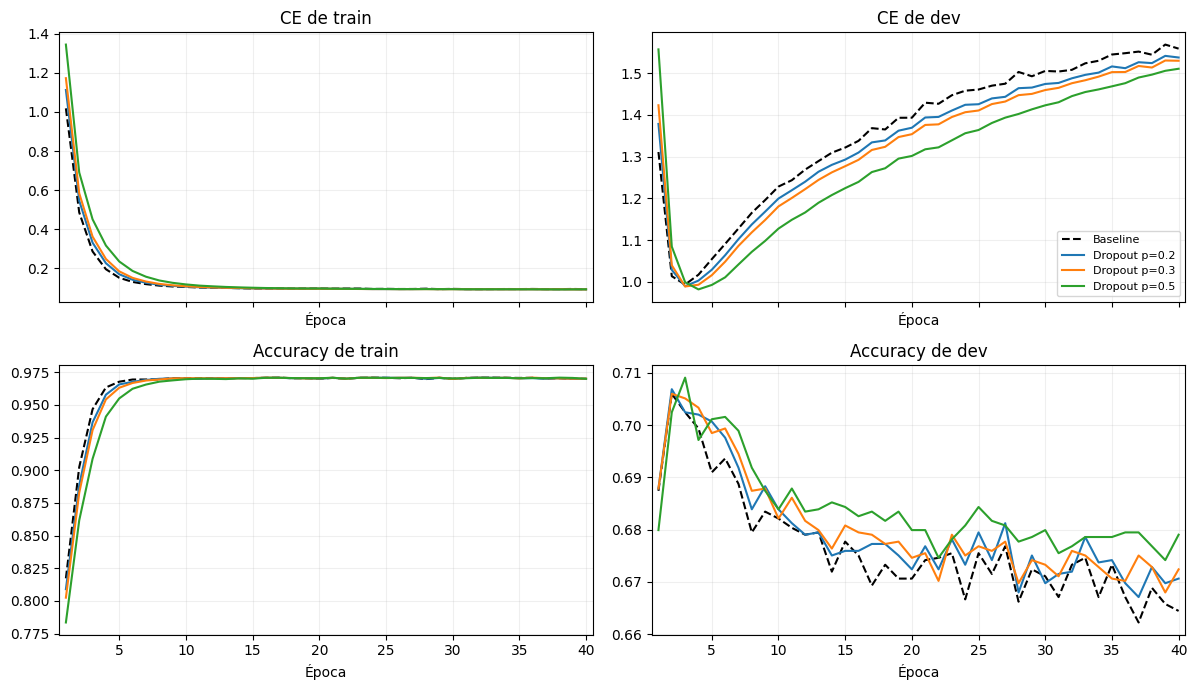

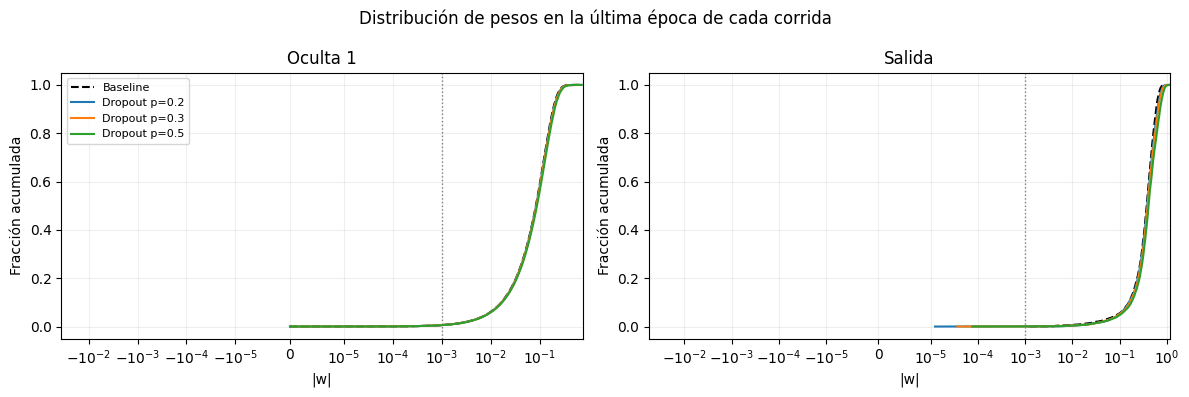

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0.0,0.0,0.0,False,Mejor dev,2,40,False,90.24525,70.60124,0.48587,1.01337,19.64401,1.60407,17.59974
1,Baseline,0.0,0.0,0.0,False,Última,40,40,False,97.00619,66.44562,0.09327,1.55916,30.56056,16.67595,17.59974
2,Dropout p=0.2,0.0,0.0,0.2,False,Mejor dev,2,40,False,88.86434,70.68966,0.54573,1.02848,18.17468,0.85476,19.02563
3,Dropout p=0.2,0.0,0.0,0.2,False,Última,40,40,False,97.00619,67.06454,0.09247,1.53790,29.94164,18.15217,19.02563
4,Dropout p=0.3,0.0,0.0,0.3,False,Mejor dev,2,40,False,88.27883,70.60124,0.58384,1.03960,17.67760,1.03257,19.25182
5,Dropout p=0.3,0.0,0.0,0.3,False,Última,40,40,False,97.01723,67.24138,0.09230,1.53008,29.77585,18.34513,19.25182
6,Dropout p=0.5,0.0,0.0,0.5,False,Mejor dev,3,40,False,90.87494,70.91070,0.45083,0.99888,19.96425,1.61735,33.89118
7,Dropout p=0.5,0.0,0.0,0.5,False,Última,40,40,False,97.00619,67.90451,0.09260,1.51092,29.10168,32.53987,33.89118


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09539,0.62606,0.59602
1,Baseline,Salida,40,0.37909,1.00001,0.00000
2,Dropout p=0.2,Oculta 1,40,0.09741,0.71778,0.60562
3,Dropout p=0.2,Salida,40,0.39653,1.08100,0.03906
4,Dropout p=0.3,Oculta 1,40,0.09835,0.65414,0.59906
5,Dropout p=0.3,Salida,40,0.40795,1.13559,0.01953
6,Dropout p=0.5,Oculta 1,40,0.10158,0.72453,0.57969
7,Dropout p=0.5,Salida,40,0.43519,1.11125,0.05859


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16964,0.04619
1,Dropout p=0.2,0.16753,0.04554
2,Dropout p=0.3,0.16621,0.04558
3,Dropout p=0.5,0.16491,0.04574


In [24]:
# Dropout: compara cada probabilidad con el baseline.

my_compare_regularization(
    {f"Dropout p={label}": result for label, result in my_dropout_runs.items()}, my_dropout_run_dir
)


### 7.5 Batch Normalization

Agregamos BatchNorm antes de LeakyReLU en la capa oculta. Se conserva la inicialización de las capas lineales y se quita el sesgo de la capa que precede a BatchNorm. L1, L2 y Dropout quedan desactivados.

In [25]:
# BatchNorm: entrena el baseline con BatchNorm en la capa oculta.

my_batchnorm_run_dir, my_batchnorm_runs = my_regularization_sweep(
    "my_batchnorm", {"solo": my_reg_settings(batchnorm=True)}
)


[my_batchnorm_solo] 1/40 | train loss=0.3193 acc=0.9412 | dev loss=1.0765 acc=0.6883 | lr=0.0025 | entrenamiento=0.89s
[my_batchnorm_solo] 2/40 | train loss=0.1275 acc=0.9688 | dev loss=1.1260 acc=0.6786 | lr=0.0025 | entrenamiento=0.57s
[my_batchnorm_solo] 3/40 | train loss=0.1058 acc=0.9698 | dev loss=1.1992 acc=0.6760 | lr=0.0025 | entrenamiento=0.59s
[my_batchnorm_solo] 4/40 | train loss=0.0988 acc=0.9705 | dev loss=1.2428 acc=0.6760 | lr=0.0025 | entrenamiento=0.59s
[my_batchnorm_solo] 5/40 | train loss=0.0976 acc=0.9701 | dev loss=1.2773 acc=0.6693 | lr=0.0025 | entrenamiento=0.61s
[my_batchnorm_solo] 6/40 | train loss=0.0957 acc=0.9706 | dev loss=1.3074 acc=0.6755 | lr=0.0025 | entrenamiento=0.60s
[my_batchnorm_solo] 7/40 | train loss=0.0950 acc=0.9704 | dev loss=1.3254 acc=0.6706 | lr=0.0025 | entrenamiento=0.59s
[my_batchnorm_solo] 8/40 | train loss=0.0949 acc=0.9707 | dev loss=1.3441 acc=0.6711 | lr=0.0025 | entrenamiento=0.59s
[my_batchnorm_solo] 9/40 | train loss=0.0944 acc

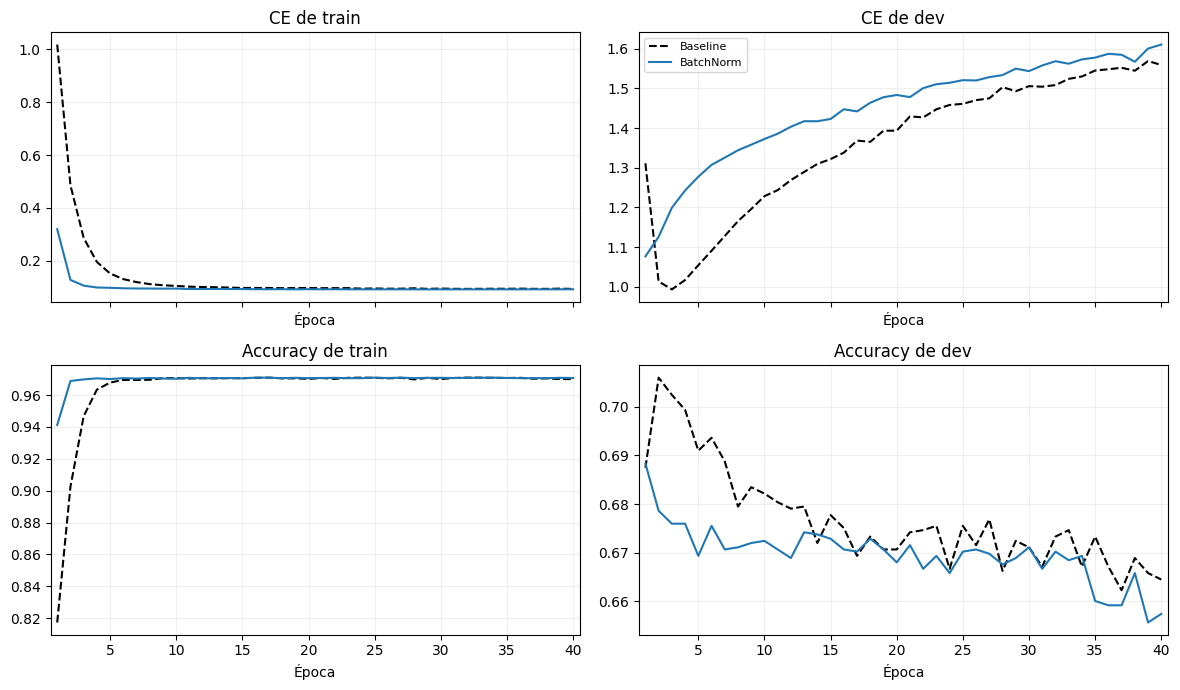

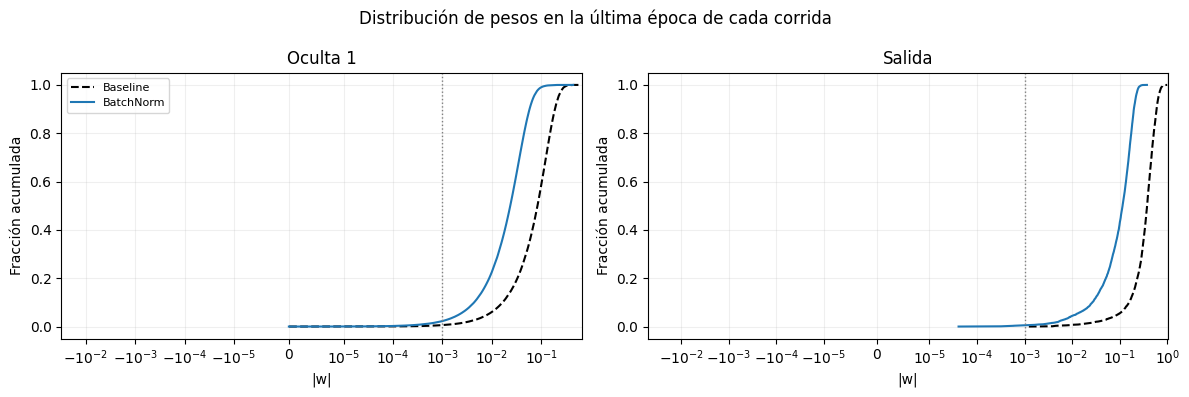

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0.0,0.0,0.0,False,Mejor dev,2,40,False,90.24525,70.60124,0.48587,1.01337,19.64401,1.60407,17.59974
1,Baseline,0.0,0.0,0.0,False,Última,40,40,False,97.00619,66.44562,0.09327,1.55916,30.56056,16.67595,17.59974
2,BatchNorm,0.0,0.0,0.0,True,Mejor dev,1,40,False,94.12285,68.83289,0.31933,1.07648,25.28995,1.26422,37.10922
3,BatchNorm,0.0,0.0,0.0,True,Última,40,40,False,97.07247,65.73828,0.09201,1.61049,31.33419,35.72620,37.10922


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09539,0.62606,0.59602
1,Baseline,Salida,40,0.37909,1.00001,0.00000
2,BatchNorm,Oculta 1,40,0.02841,0.44415,2.27500
3,BatchNorm,Salida,40,0.11524,0.37527,0.50781


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16964,0.04619
1,BatchNorm,0.13534,0.04489


In [26]:
# BatchNorm: compara la corrida con el baseline.

my_compare_regularization({"BatchNorm": my_batchnorm_runs["solo"]}, my_batchnorm_run_dir)


### 7.6 Early stopping

Probamos el baseline con paciencia de 15 épocas sin mejorar la accuracy de dev. El rombo rojo marca el corte.

[my_early_stopping_baseline] 1/40 | train loss=1.0181 acc=0.8173 | dev loss=1.3112 acc=0.6874 | lr=0.0025 | entrenamiento=0.60s
[my_early_stopping_baseline] 2/40 | train loss=0.4859 acc=0.9025 | dev loss=1.0134 acc=0.7060 | lr=0.0025 | entrenamiento=0.61s
[my_early_stopping_baseline] 3/40 | train loss=0.2863 acc=0.9468 | dev loss=0.9933 acc=0.7025 | lr=0.0025 | entrenamiento=0.60s
[my_early_stopping_baseline] 4/40 | train loss=0.1954 acc=0.9634 | dev loss=1.0169 acc=0.6994 | lr=0.0025 | entrenamiento=0.57s
[my_early_stopping_baseline] 5/40 | train loss=0.1516 acc=0.9679 | dev loss=1.0543 acc=0.6910 | lr=0.0025 | entrenamiento=0.54s
[my_early_stopping_baseline] 6/40 | train loss=0.1304 acc=0.9695 | dev loss=1.0908 acc=0.6936 | lr=0.0025 | entrenamiento=0.57s
[my_early_stopping_baseline] 7/40 | train loss=0.1191 acc=0.9695 | dev loss=1.1279 acc=0.6888 | lr=0.0025 | entrenamiento=0.57s
[my_early_stopping_baseline] 8/40 | train loss=0.1116 acc=0.9696 | dev loss=1.1654 acc=0.6795 | lr=0.002

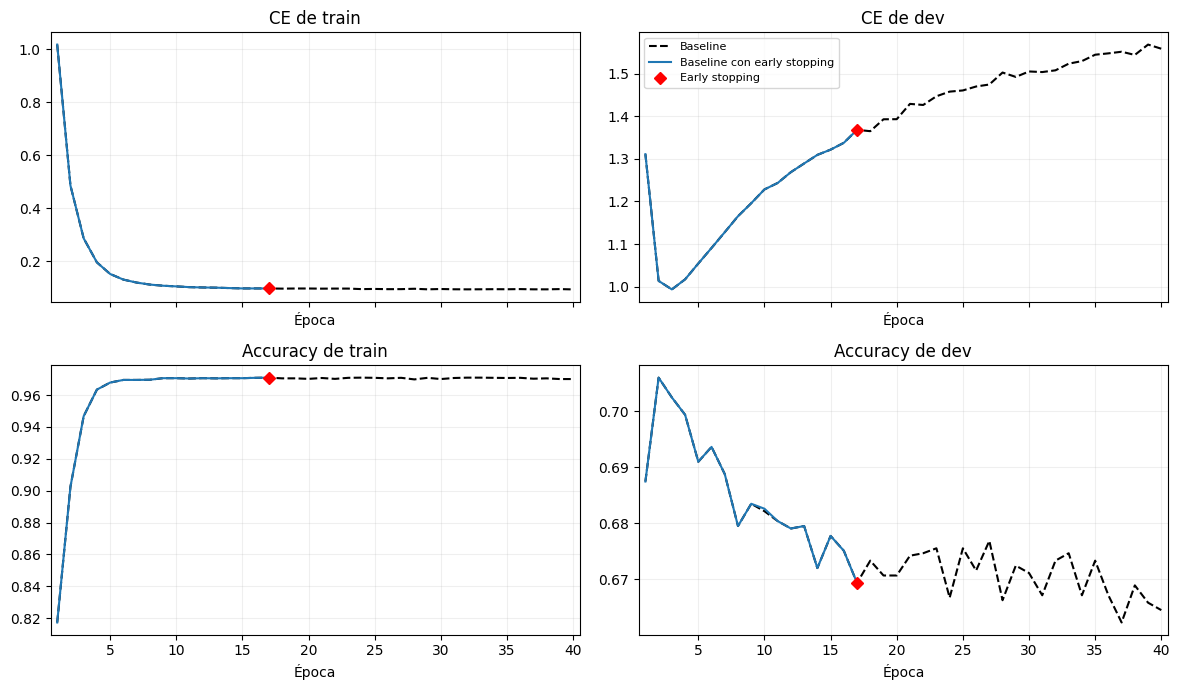

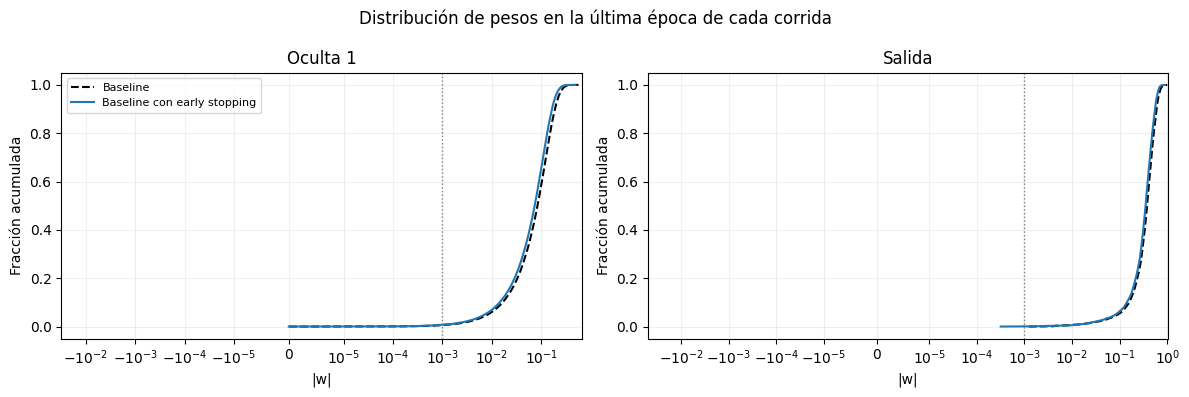

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0.0,0.0,0.0,False,Mejor dev,2,40,False,90.24525,70.60124,0.48587,1.01337,19.64401,1.60407,17.59974
1,Baseline,0.0,0.0,0.0,False,Última,40,40,False,97.00619,66.44562,0.09327,1.55916,30.56056,16.67595,17.59974
2,Baseline con early stopping,0.0,0.0,0.0,False,Mejor dev,2,17,True,90.24525,70.60124,0.48587,1.01337,19.64401,1.82574,15.98681
3,Baseline con early stopping,0.0,0.0,0.0,False,Última,17,17,True,97.09456,66.93192,0.09690,1.36847,30.16265,15.30975,15.98681


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09539,0.62606,0.59602
1,Baseline,Salida,40,0.37909,1.00001,0.00000
2,Baseline con early stopping,Oculta 1,17,0.08325,0.49624,0.69922
3,Baseline con early stopping,Salida,17,0.35110,0.86462,0.05859


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16964,0.04619
1,Baseline con early stopping,0.16964,0.04364


In [27]:
# Corre el baseline con early stopping y lo compara con el de 40 épocas.
my_early_run_dir, my_early_runs = my_regularization_sweep(
    "my_early_stopping", {"baseline": my_reg_settings(patience=15)}
)
my_compare_regularization({"Baseline con early stopping": my_early_runs["baseline"]}, my_early_run_dir)

### 7.7 L1 + L2 + Dropout + BatchNorm con early stopping

Partimos de los pesos iniciales del baseline. Usamos los coeficientes de la
mejor variante de 7.3 y el Dropout de la mejor variante de 7.4, según dev.
Agregamos BatchNorm y mantenemos una paciencia de 15 épocas.

Corremos también la combinación con el presupuesto completo, para medir
cuántas épocas ahorramos y si después del corte dev encontraba un mejor
punto. Comparamos ambas con el baseline, L1+L2, Dropout y BatchNorm.

In [28]:
# Corre la misma combinación con y sin early stopping.

def my_dev_accuracy(result):
    return result["history"]["best_value"]


my_l1_l2_best = max(my_l1_l2_runs.values(), key=my_dev_accuracy)
my_dropout_best = max(my_dropout_runs.values(), key=my_dev_accuracy)
my_all_settings = my_reg_settings(
    l1=my_l1_l2_best["config"]["lambda_l1"],
    l2=my_l1_l2_best["config"]["lambda_l2"],
    dropout=my_dropout_best["config"]["dropout"],
    batchnorm=True,
)
my_all_run_dir, my_all_runs = my_regularization_sweep(
    "my_all_regularization", {"combinada": my_all_settings}
)

my_all_early_run_dir, my_all_early_runs = my_regularization_sweep(
    "my_all_early_stopping",
    {"combinada": {**my_all_settings, "patience": EARLY_STOPPING_PATIENCE}},
)

[my_all_regularization_combinada] 1/40 | train loss=0.4983 acc=0.9019 | dev loss=1.0925 acc=0.7025 | lr=0.0025 | entrenamiento=0.71s
[my_all_regularization_combinada] 2/40 | train loss=0.1935 acc=0.9590 | dev loss=1.0657 acc=0.6901 | lr=0.0025 | entrenamiento=0.72s
[my_all_regularization_combinada] 3/40 | train loss=0.1281 acc=0.9674 | dev loss=1.1449 acc=0.6804 | lr=0.0025 | entrenamiento=0.85s
[my_all_regularization_combinada] 4/40 | train loss=0.1074 acc=0.9693 | dev loss=1.2250 acc=0.6751 | lr=0.0025 | entrenamiento=0.72s
[my_all_regularization_combinada] 5/40 | train loss=0.1024 acc=0.9697 | dev loss=1.2925 acc=0.6689 | lr=0.0025 | entrenamiento=0.69s
[my_all_regularization_combinada] 6/40 | train loss=0.0987 acc=0.9703 | dev loss=1.3420 acc=0.6667 | lr=0.0025 | entrenamiento=0.87s
[my_all_regularization_combinada] 7/40 | train loss=0.0973 acc=0.9702 | dev loss=1.3955 acc=0.6662 | lr=0.0025 | entrenamiento=0.88s
[my_all_regularization_combinada] 8/40 | train loss=0.0978 acc=0.9701

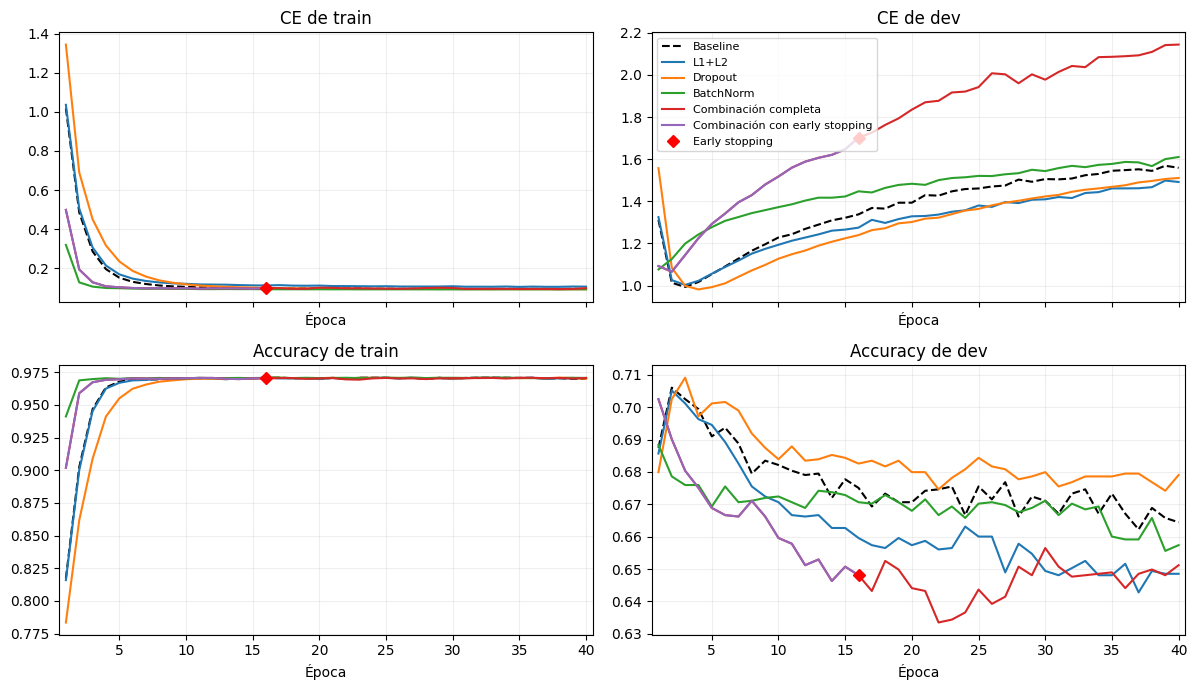

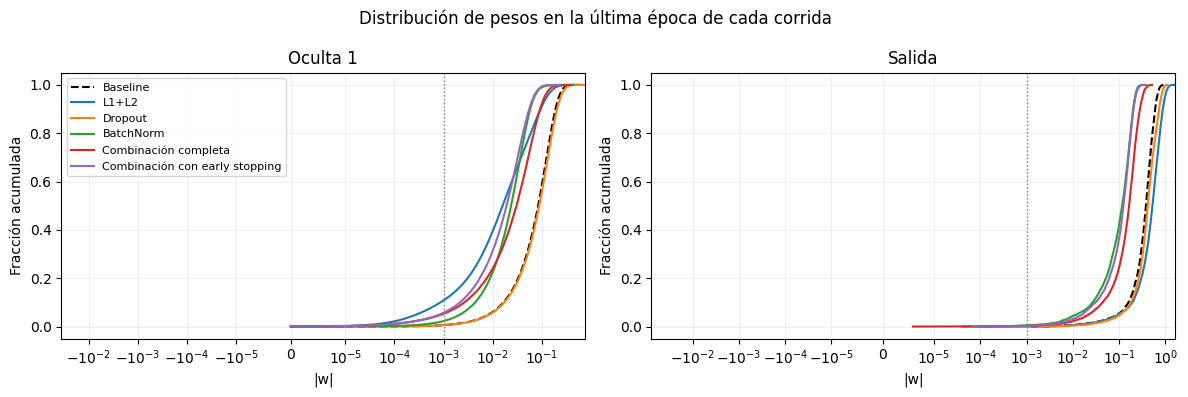

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0.0,0.00000,0.0,False,Mejor dev,2,40,False,90.24525,70.60124,0.48587,1.01337,19.64401,1.60407,17.59974
1,Baseline,0.0,0.00000,0.0,False,Última,40,40,False,97.00619,66.44562,0.09327,1.55916,30.56056,16.67595,17.59974
2,L1+L2,0.0,0.00001,0.0,False,Mejor dev,2,40,False,90.01326,70.51282,0.50527,1.02569,19.50044,0.90101,21.10694
3,L1+L2,0.0,0.00001,0.0,False,Última,40,40,False,97.06142,64.85411,0.10578,1.49183,32.20731,20.14691,21.10694
4,Dropout,0.0,0.00000,0.5,False,Mejor dev,3,40,False,90.87494,70.91070,0.45083,0.99888,19.96425,1.61735,33.89118
5,Dropout,0.0,0.00000,0.5,False,Última,40,40,False,97.00619,67.90451,0.09260,1.51092,29.10168,32.53987,33.89118
6,BatchNorm,0.0,0.00000,0.0,True,Mejor dev,1,40,False,94.12285,68.83289,0.31933,1.07648,25.28995,1.26422,37.10922
7,BatchNorm,0.0,0.00000,0.0,True,Última,40,40,False,97.07247,65.73828,0.09201,1.61049,31.33419,35.72620,37.10922
8,Combinación completa,0.0,0.00001,0.5,True,Mejor dev,1,40,False,90.19001,70.24757,0.49835,1.09253,19.94244,1.00484,42.86672
9,Combinación completa,0.0,0.00001,0.5,True,Última,40,40,False,97.07247,65.11936,0.09779,2.14438,31.95311,41.40347,42.86672


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09539,0.62606,0.59602
1,Baseline,Salida,40,0.37909,1.00001,0.00000
2,L1+L2,Oculta 1,40,0.03385,0.62613,10.83234
3,L1+L2,Salida,40,0.53160,1.55389,0.01953
4,Dropout,Oculta 1,40,0.10158,0.72453,0.57969
5,Dropout,Salida,40,0.43519,1.11125,0.05859
6,BatchNorm,Oculta 1,40,0.02841,0.44415,2.27500
7,BatchNorm,Salida,40,0.11524,0.37527,0.50781
8,Combinación completa,Oculta 1,40,0.04029,0.38149,5.29445
9,Combinación completa,Salida,40,0.16480,0.51506,0.23438


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16964,0.04619
1,L1+L2,0.16801,0.04757
2,Dropout,0.16491,0.04574
3,BatchNorm,0.13534,0.04489
4,Combinación completa,0.16203,0.05109
5,Combinación con early stopping,0.16203,0.05247


In [29]:
# Compara las curvas y marca dónde se detuvo la combinación.
my_compare_regularization({
    "L1+L2": my_l1_l2_best,
    "Dropout": my_dropout_best,
    "BatchNorm": my_batchnorm_runs["solo"],
    "Combinación completa": my_all_runs["combinada"],
    "Combinación con early stopping": my_all_early_runs["combinada"],
}, my_all_early_run_dir)

## 8. Búsqueda con Optuna

Cada trial usa la misma opción en todas las capas ocultas: sin
regularización, BatchNorm o Dropout. Probamos BatchNorm y Dropout por
separado porque pueden interferir.

Hacemos 24 trials con LR fijo y 24 con CLR. Cada estudio arranca con un
trial por opción y profundidad. Optuna elige las neuronas por capa, el
batch y el LR. Si toca Dropout, también elige `p` de 0,1 a 0,6 en pasos de 0,1.

El barrido inicial de LR usa la arquitectura del baseline. Dejamos que
todos los trials entrenen 40 épocas para darles tiempo a los que mejoran
más lento. Elegimos la mejor época por accuracy de dev.

In [30]:
# Comprueba la GPU y fija el presupuesto de búsqueda.
from pathlib import Path
import hashlib
import json
import shutil
import sqlite3
from contextlib import closing
from importlib.util import find_spec
import joblib
import pandas as pd

SEARCH_SEED = SEED
SEARCH_EPOCHS = MAX_EPOCHS
TRIALS_PER_POLICY = 24  # cambiar manualmente
CLR_HALF_EPOCHS = 2
LR_RANGE_EPOCHS = 6
LR_RANGE_LOW, LR_RANGE_HIGH = 1e-5, 1e-2
FIXED_LR_LOW = 1e-4
DEPTH_OPTIONS = [1, 2, 3]
WIDTH_OPTIONS = [128, 256, 512]
DROPOUT_RANGE = (0.1, 0.6, 0.1)
REGULARIZATION_OPTIONS = [0, "batchnorm", "dropout"]

search_device = device
if search_device.type not in ("cuda", "xpu"):
    raise RuntimeError("Seleccioná el kernel local mlp-gpu (Intel XPU) o activá GPU en Colab.")
gpu = torch.xpu if search_device.type == "xpu" else torch.cuda
search_gpu_name = gpu.get_device_name(search_device)

if find_spec("google") and find_spec("google.colab"):
    from google.colab import drive

    drive.mount("/content/drive")
    results_root = Path("/content/drive/MyDrive/TP3_RN_resultados")
    local_db_root = Path("/content/TP3_RN_db")
else:
    project = Path.cwd()
    if (project / "TP RN Regularización Bonacina").is_dir():
        project /= "TP RN Regularización Bonacina"
    results_root = project / ".experimentos" / "my_gpu_search"
    local_db_root = results_root

print(f"{search_device.type}: {search_gpu_name}")

xpu: Intel(R) Arc(TM) 140V GPU (16GB)


In [31]:
# Ajusta el TF-IDF de búsqueda con train y transforma dev.
train_clean = [preprocess_text(text) for text in train_texts_raw]
dev_clean = [preprocess_text(text) for text in dev_texts_raw]
X_search_train, X_search_dev, search_vectorizer = vectorize_data(
    train_clean, dev_clean, ngram_range=(1, 1), max_features=5000, min_df=1,
)
search_train = to_tensor_dataset(X_search_train, y_train)
search_dev = to_tensor_dataset(X_search_dev, y_dev)
del X_search_train, X_search_dev

protocol = {
    "version": 4, "seed": SEARCH_SEED, "split_id": DATA_SPLIT_ID,
    "activation": ACTIVATION, "depth_options": DEPTH_OPTIONS, "width_options": WIDTH_OPTIONS,
    "batch_sizes": BATCH_SIZES, "fixed_lr_low": FIXED_LR_LOW,
    "dropout_range": DROPOUT_RANGE,
    "baseline": {"hidden_units": BASELINE_HIDDEN_UNITS,
                 "batch_size": BASELINE_BATCH_SIZE, "lr": BASELINE_LR},
    "device_type": search_device.type,
    "epochs": SEARCH_EPOCHS, "half_cycle_epochs": CLR_HALF_EPOCHS,
    "lr_range_epochs": LR_RANGE_EPOCHS,
    "lr_range": [LR_RANGE_LOW, LR_RANGE_HIGH],
    "regularization_options": REGULARIZATION_OPTIONS,
    "train_size": len(y_train), "dev_size": len(y_dev),
    "feature_names": list(search_vectorizer.get_feature_names_out()),
}
signature = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()[:12]
search_dir = results_root / signature
search_dir.mkdir(parents=True, exist_ok=True)


def save_json(path, value):
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    temp.replace(path)


save_json(search_dir / "protocol.json", protocol)


def make_search_model(input_dim, config):
    mode = config["regularizacion"]
    set_seed(SEARCH_SEED)
    return my_MLP_model(
        input_dim, NUM_CLASSES, config["hidden_units"], config.get("activation", ACTIVATION),
        batchnorm=mode == "batchnorm",
        dropout=config["dropout"] if mode == "dropout" else 0.0,
    ).to(search_device)

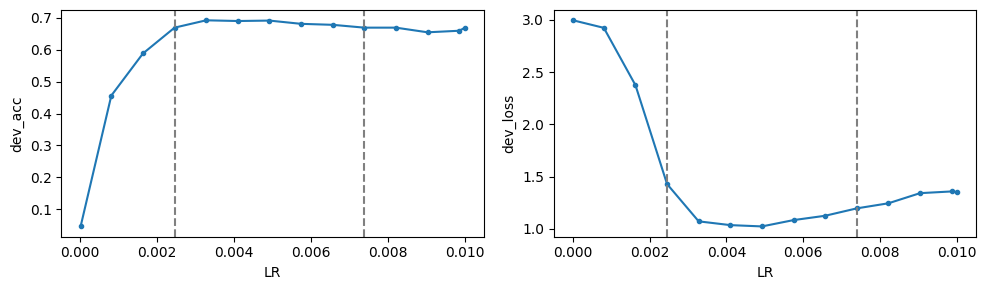

In [32]:
# Hace el LR range test con una copia nueva del baseline.
def run_lr_range_test():
    loaders = make_loaders(search_train, search_dev, batch_size=BASELINE_BATCH_SIZE, seed=SEARCH_SEED)
    train_loader, _, dev_loader = loaders
    model = make_search_model(search_train.tensors[0].shape[1], {
        "hidden_units": BASELINE_HIDDEN_UNITS, "regularizacion": 0,
    })
    optimizer = create_optimizer(model, "Adam", lr=LR_RANGE_LOW)
    total_steps = LR_RANGE_EPOCHS * len(train_loader)
    probe_every = max(1, len(train_loader) // 2)
    probes = []
    step = 0
    for _ in range(LR_RANGE_EPOCHS):
        for xb, yb in train_loader:
            model.train()
            lr = LR_RANGE_LOW + (LR_RANGE_HIGH - LR_RANGE_LOW) * step / (total_steps - 1)
            optimizer.param_groups[0]["lr"] = lr
            optimizer.zero_grad(set_to_none=True)
            loss = classification_cost(model(xb.to(search_device)), yb.to(search_device))
            if not torch.isfinite(loss):
                return probes
            loss.backward()
            optimizer.step()
            step += 1
            if step == 1 or step % probe_every == 0 or step == total_steps:
                dev_loss, dev_acc = evaluate_model(model, dev_loader)
                if not np.isfinite(dev_loss):
                    return probes
                probes.append({"step": step, "lr": lr, "dev_acc": dev_acc, "dev_loss": dev_loss})
    return probes


def lr_bounds(probes):
    if len(probes) < 3:
        raise RuntimeError("El LR range test necesita más puntos válidos.")
    peak = max(range(len(probes)), key=lambda i: probes[i]["dev_acc"])
    first = next(p for p in probes[:peak + 1] if p["dev_acc"] >= probes[peak]["dev_acc"] - 0.02)
    upper = next(
        (p for p in probes[peak + 1:] if p["dev_acc"] <= probes[peak]["dev_acc"] - 0.015),
        probes[-1],
    )
    return {"base_lr": min(first["lr"], upper["lr"] / 3), "max_lr": upper["lr"]}


range_path = search_dir / "lr_range.json"
if range_path.is_file():
    range_result = json.loads(range_path.read_text(encoding="utf-8"))
else:
    range_probes = run_lr_range_test()
    range_result = {"probes": range_probes, **lr_bounds(range_probes)}
    save_json(range_path, range_result)

range_table = pd.DataFrame(range_result["probes"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ("dev_acc", "dev_loss")):
    ax.plot(range_table["lr"], range_table[metric], marker=".")
    ax.axvline(range_result["base_lr"], color="gray", linestyle="--")
    ax.axvline(range_result["max_lr"], color="gray", linestyle="--")
    ax.set(xlabel="LR", ylabel=metric)
fig.tight_layout()
plt.show()

In [33]:
# Define el espacio de búsqueda y configura Adam con LR fijo o triangular2.
def suggest_search_config(trial, policy):
    mode = trial.suggest_categorical("regularizacion", REGULARIZATION_OPTIONS)
    depth = trial.suggest_int("n_hidden_layers", DEPTH_OPTIONS[0], DEPTH_OPTIONS[-1])
    hidden_units = [
        trial.suggest_categorical(f"units_layer_{i}", WIDTH_OPTIONS)
        for i in range(1, depth + 1)
    ]
    batch_size = trial.suggest_categorical("batch_size", BATCH_SIZES)
    low, high = range_result["base_lr"], range_result["max_lr"]
    config = {
        "regularizacion": mode, "batch_size": batch_size,
        "hidden_units": hidden_units, "activation": ACTIVATION,
        "policy": policy, "base_lr": low, "half_cycle_epochs": CLR_HALF_EPOCHS,
        "dropout": 0.0,
    }
    if policy == "clr":
        config["lr"] = trial.suggest_float("max_lr", low * 1.5, high, log=True)
        config["base_lr"] = trial.suggest_float("base_lr", min(LR_RANGE_LOW, low), low, log=True)
    else:
        config["lr"] = trial.suggest_float(
            "lr", min(FIXED_LR_LOW, low, BASELINE_LR), max(high, BASELINE_LR), log=True,
        )
    if mode == "dropout":
        dropout_min, dropout_max, dropout_step = DROPOUT_RANGE
        config["dropout"] = trial.suggest_float("dropout", dropout_min, dropout_max, step=dropout_step)
    return config


def fit_search_model(config, epochs, epoch_callback=None, batch_callback=None):
    loaders = make_loaders(
        search_train, search_dev, batch_size=config["batch_size"],
        seed=SEARCH_SEED, batchnorm=config["regularizacion"] == "batchnorm",
    )
    model = make_search_model(search_train.tensors[0].shape[1], config)
    optimizer = create_optimizer(model, "Adam", lr=config["lr"], betas=(0.9, 0.999))
    scheduler = None
    if config["policy"] == "clr":
        scheduler = optim.lr_scheduler.CyclicLR(
            optimizer, base_lr=config["base_lr"], max_lr=config["lr"],
            step_size_up=config["half_cycle_epochs"] * len(loaders[0]),
            mode="triangular2", cycle_momentum=False,
        )
    history = train_mlp_model(
        model, *loaders, optimizer, epochs=epochs, scheduler=scheduler,
        patience=None, monitor="val_acc", verbose=False,
        epoch_callback=epoch_callback, batch_callback=batch_callback,
    )
    return model, history

In [34]:
# Guarda la trayectoria de cada trial.
def search_objective(trial, policy):
    config = suggest_search_config(trial, policy)
    trial.set_user_attr("config", config)
    folder = search_dir / policy
    folder.mkdir(exist_ok=True)
    partial_history = {}
    lr_trace = []

    def capture_epoch(model, history):
        partial_history.update(history)

    def capture_batch(epoch, batch, values):
        lr_trace.append(values["lr"])

    try:
        _, history = fit_search_model(
            config, SEARCH_EPOCHS,
            epoch_callback=capture_epoch, batch_callback=capture_batch,
        )
    except FloatingPointError:
        trial.set_user_attr("diverged", True)
        save_json(folder / f"trial_{trial.number:03}.json", {
            "config": config, "history": partial_history, "lr_by_batch": lr_trace,
            "status": "diverged",
        })
        raise

    trial.set_user_attr("best_epoch", history["best_epoch"])
    save_json(folder / f"trial_{trial.number:03}.json", {
        "config": config, "history": history, "lr_by_batch": lr_trace, "status": "complete",
    })
    return history["best_value"]

In [35]:
# Ejecuta o retoma los dos estudios y guarda una copia de SQLite por trial.
def run_search(policy):
    local_dir = local_db_root / signature if local_db_root != results_root else search_dir
    local_dir.mkdir(parents=True, exist_ok=True)
    backup = search_dir / f"{policy}.sqlite3"
    database = local_dir / backup.name
    if backup != database and backup.is_file() and not database.is_file():
        shutil.copy2(backup, database)

    def save_study(study, trial):
        if database != backup:
            # SQLite trabaja en el disco local; Drive recibe una copia cerrada.
            temp_local = database.with_suffix(".snapshot")
            with closing(sqlite3.connect(database)) as origin, closing(sqlite3.connect(temp_local)) as snapshot:
                origin.backup(snapshot)
            temp_backup = backup.with_suffix(".tmp")
            shutil.copy2(temp_local, temp_backup)
            temp_backup.replace(backup)
        print(f"{policy} | trial {trial.number} | {trial.state.name} | dev={trial.value}")

    db_url = database.resolve().as_posix().replace("{", "{{").replace("}", "}}")
    study = optuna.create_study(
        study_name=policy, storage=f"sqlite:///{db_url}", load_if_exists=True,
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEARCH_SEED),
        pruner=optuna.pruners.NopPruner(),
    )
    if not study.trials:
        for depth in DEPTH_OPTIONS:
            for mode in REGULARIZATION_OPTIONS:
                plan = {"regularizacion": mode, "n_hidden_layers": depth}
                if depth == len(BASELINE_HIDDEN_UNITS) and mode == 0:
                    plan["batch_size"] = BASELINE_BATCH_SIZE
                    plan.update({f"units_layer_{i}": units for i, units in enumerate(BASELINE_HIDDEN_UNITS, 1)})
                    if policy == "fixed":
                        plan["lr"] = BASELINE_LR
                study.enqueue_trial(plan)

    finished = sum(
        t.state == optuna.trial.TrialState.COMPLETE
        or (t.state == optuna.trial.TrialState.FAIL and t.user_attrs.get("diverged", False))
        for t in study.trials
    )
    study.optimize(
        lambda trial: search_objective(trial, policy),
        n_trials=max(0, TRIALS_PER_POLICY - finished), callbacks=[save_study],
        catch=(FloatingPointError,),
    )
    study.trials_dataframe().to_csv(search_dir / f"trials_{policy}.csv", index=False)
    return study


search_studies = {policy: run_search(policy) for policy in ("fixed", "clr")}

best_by_policy = {policy: study.best_trial for policy, study in search_studies.items()}
baseline_trial = search_studies["fixed"].trials[0]
assert baseline_trial.state == optuna.trial.TrialState.COMPLETE

# El test se abre después de elegir las corridas con dev.
final_plan = {}
labels_by_trial = {}
dev_rows = []


def add_final_trial(label, policy, trial):
    key = (policy, trial.number)
    if key in labels_by_trial:
        final_plan[labels_by_trial[key]]["roles"].append(label)
    else:
        labels_by_trial[key] = label
        final_plan[label] = {"trial": trial.number, **trial.user_attrs, "roles": [label]}


add_final_trial("baseline", "fixed", baseline_trial)
add_final_trial("mejor_lr_fijo", "fixed", best_by_policy["fixed"])
add_final_trial("mejor_clr", "clr", best_by_policy["clr"])

regularized_candidates = []
for policy, study in search_studies.items():
    for mode in REGULARIZATION_OPTIONS:
        trials = [t for t in study.trials if t.params.get("regularizacion") == mode]
        completed = [t for t in trials if t.state == optuna.trial.TrialState.COMPLETE]
        if not completed:
            dev_rows.append({"politica": policy, "regularizacion": mode, "completos": 0, "trials": len(trials)})
            continue
        best = max(completed, key=lambda t: t.value)
        config = best.user_attrs["config"]
        dev_rows.append({
            "politica": policy, "regularizacion": mode, "completos": len(completed), "trials": len(trials),
            "trial": best.number, "capas": config["hidden_units"], "batch_size": config["batch_size"],
            "dropout": config["dropout"], "accuracy_dev": best.value,
        })
        if mode != 0:
            regularized_candidates.append((policy, best))

if regularized_candidates:
    policy, best = max(regularized_candidates, key=lambda entry: entry[1].value)
    add_final_trial("mejor_regularizado", policy, best)

save_json(search_dir / "final_plan.json", final_plan)
dev_summary = pd.DataFrame(dev_rows)
dev_summary.to_csv(search_dir / "dev_summary.csv", index=False)
display(dev_summary.round(5))

[I 2026-11-23 00:17:52,019] Using an existing study with `study_name='fixed'` instead of creating a new one.
[I 2026-11-23 00:17:52,111] Using an existing study with `study_name='clr'` instead of creating a new one.


,politica,regularizacion,completos,trials,trial,capas,batch_size,dropout,accuracy_dev
0,fixed,0,10,10,18,[512],64,0.0,0.70999
1,fixed,batchnorm,3,3,1,[256],256,0.0,0.68081
2,fixed,dropout,11,11,12,[512],256,0.6,0.70778
3,clr,0,5,5,0,[256],128,0.0,0.70292
4,clr,batchnorm,3,3,1,[128],128,0.0,0.66888
5,clr,dropout,16,16,11,[512],128,0.6,0.70557


In [36]:
# Muestra la configuración completa del mejor trial de cada grupo (semilla 9).
from pathlib import Path
import json
import pandas as pd

seed9_study_dir = search_dir
seed9_protocol = json.loads((seed9_study_dir / "protocol.json").read_text(encoding="utf-8"))
assert seed9_protocol["seed"] == 9


def seed9_parameters(config):
    clr = config["policy"] == "clr"
    return {
        "semilla": seed9_protocol["seed"],
        "épocas máx.": seed9_protocol["epochs"],
        "activación": config["activation"],
        "capas ocultas": len(config["hidden_units"]),
        "neuronas por capa": config["hidden_units"],
        "batch size": config["batch_size"],
        "regularización": config["regularizacion"],
        "dropout": config["dropout"] if config["regularizacion"] == "dropout" else None,
        "política LR": "CLR" if clr else "Fijo",
        "LR fijo": None if clr else config["lr"],
        "LR base": config["base_lr"] if clr else None,
        "LR pico inicial": config["lr"] if clr else None,
        "medio ciclo (épocas)": config["half_cycle_epochs"] if clr else None,
    }


seed9_dev = pd.read_csv(seed9_study_dir / "dev_summary.csv")
seed9_winners = []
for row in seed9_dev.dropna(subset=["trial"]).itertuples(index=False):
    number = int(row.trial)
    trial_path = seed9_study_dir / row.politica / f"trial_{number:03}.json"
    trial = json.loads(trial_path.read_text(encoding="utf-8"))
    seed9_winners.append({
        "trial": number, **seed9_parameters(trial["config"]),
        "mejor época dev": trial["history"]["best_epoch"],
        "accuracy dev": row.accuracy_dev,
        "trials completos": row.completos, "trials": row.trials,
    })

with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(pd.DataFrame(seed9_winners))

,trial,semilla,épocas máx.,activación,capas ocultas,neuronas por capa,batch size,regularización,dropout,política LR,LR fijo,LR base,LR pico inicial,medio ciclo (épocas),mejor época dev,accuracy dev,trials completos,trials
0,18,9,40,leaky_relu,1,[512],64,0,NaN,Fijo,0.0002804395,NaN,NaN,NaN,6,0.7099911583,10,10
1,1,9,40,leaky_relu,1,[256],256,batchnorm,NaN,Fijo,0.0006054298,NaN,NaN,NaN,3,0.6808134394,3,3
2,12,9,40,leaky_relu,1,[512],256,dropout,0.6,Fijo,0.0004204324,NaN,NaN,NaN,10,0.7077807250,11,11
3,0,9,40,leaky_relu,1,[256],128,0,NaN,CLR,NaN,0.0001585878,0.0037220924,2.0,2,0.7029177719,5,5
4,1,9,40,leaky_relu,1,[128],128,batchnorm,NaN,CLR,NaN,0.0000670325,0.0039171364,2.0,1,0.6688770999,3,3
5,11,9,40,leaky_relu,1,[512],128,dropout,0.6,CLR,NaN,0.0002885453,0.0043548027,2.0,5,0.7055702918,16,16


## 9. Entrenamiento final y evaluación

Evaluamos el baseline, el mejor trial con LR fijo, el mejor con CLR y el
mejor entre BatchNorm y Dropout. Si un trial ocupa dos lugares, lo
evaluamos una vez. Elegimos los modelos y la época por accuracy de dev.
Mostramos los histogramas de los pesos de esa época, separados por capa.

Reportamos el test oficial completo y, aparte, la accuracy en los documentos
cuyo texto no aparece en el train oficial. Para identificar una copia
ignoramos diferencias de mayúsculas y espacios.

In [37]:
# Carga el plan elegido en dev y prepara los modelos finales.
plan_path = search_dir / "final_plan.json"
if not plan_path.is_file():
    raise FileNotFoundError("Primero completá la búsqueda de la sección 8.")
final_plan = json.loads(plan_path.read_text(encoding="utf-8"))
if any(row["config"].get("regularizacion") not in REGULARIZATION_OPTIONS for row in final_plan.values()):
    raise ValueError("Volvé a correr la sección 8 con las opciones actuales de regularización.")
final_dir = search_dir / "final"
final_dir.mkdir(exist_ok=True)
joblib.dump(search_vectorizer, final_dir / "vectorizer.joblib")
save_json(final_dir / "plan.json", final_plan)
final_models, final_histories = {}, {}
for label, plan in final_plan.items():
    config = plan["config"]
    folder = final_dir / label
    folder.mkdir(exist_ok=True)
    best_path = folder / "model_best.pt"
    history_path = folder / "history.json"
    batches_path = folder / "batches.csv"
    settings_path = folder / "config.json"
    settings = {
        **plan, "seed": SEARCH_SEED, "epochs": SEARCH_EPOCHS,
        "device": str(search_device), "gpu": search_gpu_name,
        "torch_version": str(torch.__version__),
    }
    if all(path.is_file() for path in (settings_path, best_path, history_path, batches_path)):
        saved = json.loads(settings_path.read_text(encoding="utf-8"))
        if saved == settings:
            model = make_search_model(search_train.tensors[0].shape[1], config)
            model.load_state_dict(torch.load(best_path, map_location="cpu", weights_only=True))
            final_models[label] = model.eval()
            final_histories[label] = json.loads(history_path.read_text(encoding="utf-8"))
            print(f"{label}: modelo guardado")
            continue

    lr_trace = []

    def record_final_batch(epoch, batch, values):
        lr_trace.append({"epoch": epoch, "batch": batch, **values})

    model, history = fit_search_model(config, SEARCH_EPOCHS, batch_callback=record_final_batch)
    torch.save({key: tensor.detach().cpu() for key, tensor in model.state_dict().items()}, best_path)
    save_json(history_path, history)
    pd.DataFrame(lr_trace).to_csv(batches_path, index=False)
    save_json(settings_path, settings)
    final_models[label], final_histories[label] = model, history
    print(f"{label}: modelo entrenado")

baseline: modelo guardado
mejor_lr_fijo: modelo guardado
mejor_clr: modelo guardado
mejor_regularizado: modelo guardado


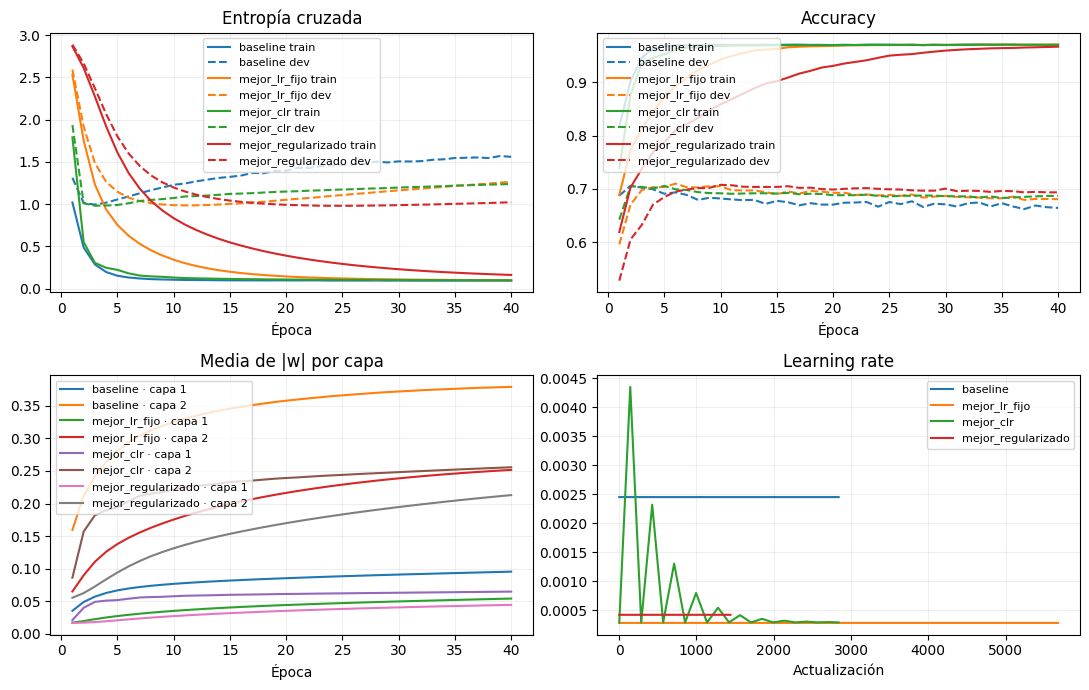

In [38]:
# Grafica pérdida, accuracy, pesos y LR de las corridas finales.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for label in final_models:
    folder = final_dir / label
    history = final_histories[label]
    epochs = range(1, history["epochs_completed"] + 1)
    for ax, metric in zip(axes[0], ("loss", "acc")):
        train_line, = ax.plot(epochs, history[f"train_{metric}"], label=f"{label} train")
        ax.plot(epochs, history[f"val_{metric}"], color=train_line.get_color(),
                linestyle="--", label=f"{label} dev")
    for layer_index, name in enumerate(history["weights"][0], start=1):
        values = [w[name]["mean_abs"] for w in history["weights"]]
        axes[1, 0].plot(epochs, values, label=f"{label} · capa {layer_index}")
    batches = pd.read_csv(folder / "batches.csv")
    axes[1, 1].plot(np.arange(1, len(batches) + 1), batches["lr"], label=label)

for ax, title, xlabel in zip(
    axes.flat, ("Entropía cruzada", "Accuracy", "Media de |w| por capa", "Learning rate"),
    ("Época", "Época", "Época", "Actualización"),
):
    ax.set(title=title, xlabel=xlabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(final_dir / "training_curves.png", dpi=150)
plt.show()

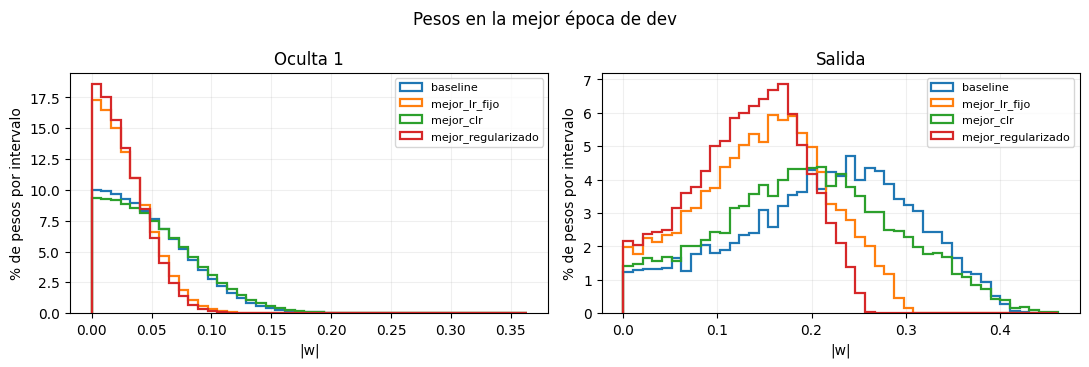

In [39]:
# Compara los histogramas de |w| de los modelos finales, capa por capa.
layer_weights = {}
for label, model in final_models.items():
    linear_layers = [layer for layer in model.modules() if isinstance(layer, nn.Linear)]
    for i, layer in enumerate(linear_layers[:-1], start=1):
        layer_weights.setdefault(f"Oculta {i}", {})[label] = layer.weight.detach().abs().cpu().numpy().ravel()
    layer_weights.setdefault("Salida", {})[label] = linear_layers[-1].weight.detach().abs().cpu().numpy().ravel()

layer_titles = [name for name in layer_weights if name != "Salida"] + ["Salida"]
colors = dict(zip(final_models, plt.get_cmap("tab10").colors))
n_rows = (len(layer_titles) + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(11, 3.7 * n_rows), squeeze=False)
for ax, title in zip(axes.flat, layer_titles):
    weights_by_model = layer_weights[title]
    # Mismos intervalos por capa. Usamos porcentajes porque los modelos tienen distintos tamaños.
    xmax = max(values.max() for values in weights_by_model.values())
    bins = np.linspace(0, xmax if xmax > 0 else 1.0, 46)
    for label, values in weights_by_model.items():
        ax.hist(values, bins=bins, weights=np.full(len(values), 100.0 / len(values)),
                histtype="step", linewidth=1.6, color=colors[label], label=label)
    ax.set(title=title, xlabel="|w|", ylabel="% de pesos por intervalo")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

for ax in list(axes.flat)[len(layer_titles):]:
    ax.set_visible(False)
fig.suptitle("Pesos en la mejor época de dev")
fig.tight_layout()
fig.savefig(final_dir / "weight_histograms.png", dpi=150)
plt.show()

Test: 7532 documentos | Copias del train oficial: 18


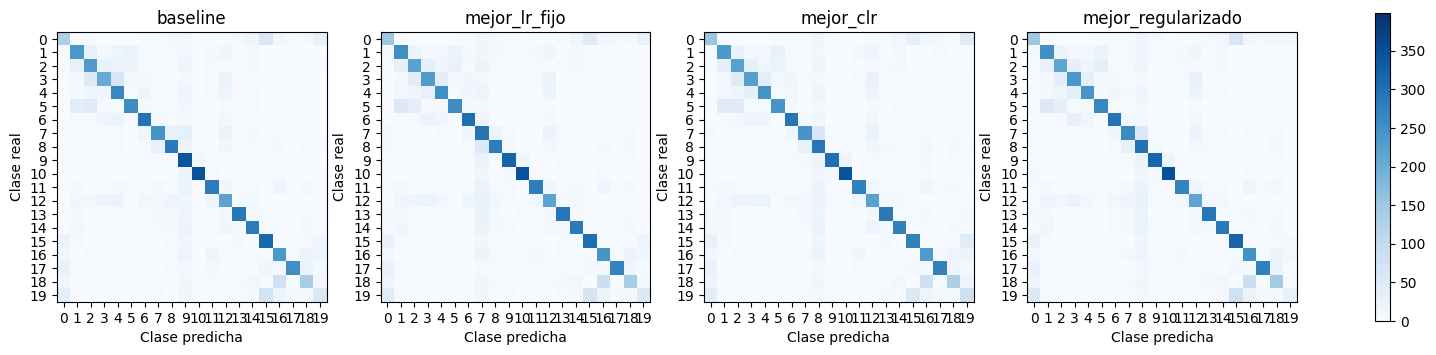

,modelo,roles,regularizacion,dropout,capas,politica_lr,trial,epoca,accuracy_dev,accuracy_test,ce_test,accuracy_test_sin_copias,n_test_sin_copias
0,baseline,baseline,0,0.0,[256],fixed,0,2,0.70601,0.65215,1.17781,0.65238,7514
1,mejor_lr_fijo,mejor_lr_fijo,0,0.0,[512],fixed,18,6,0.70999,0.66171,1.22007,0.66223,7514
2,mejor_clr,mejor_clr,dropout,0.6,[512],clr,11,5,0.70557,0.64312,1.21775,0.64347,7514
3,mejor_regularizado,mejor_regularizado,dropout,0.6,[512],fixed,12,10,0.70778,0.65799,1.31807,0.65850,7514


In [40]:
# Aplica el vocabulario de train al test y guarda métricas y matrices.
newsgroups_test = fetch_20newsgroups(
    subset="test", remove=("headers", "footers", "quotes"),
)
assert newsgroups_test.target_names == class_names
test_texts_raw, y_test = newsgroups_test.data, newsgroups_test.target
test_overlap = np.array([document_key(text) in known_document_keys for text in test_texts_raw])
print(f"Test: {len(y_test)} documentos | Copias del train oficial: {test_overlap.sum()}")

test_clean = [preprocess_text(text) for text in test_texts_raw]
X_final_test = search_vectorizer.transform(test_clean)
final_test_loader = DataLoader(to_tensor_dataset(X_final_test, y_test), batch_size=256)


@torch.no_grad()
def predict_test(model, loader):
    model.eval()
    loss_sum, predictions = 0.0, []
    for xb, yb in loader:
        logits = model(xb.to(search_device))
        loss_sum += classification_cost(logits, yb.to(search_device), reduction="sum").item()
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
    return loss_sum / len(loader.dataset), predictions


summary = []
fig, axes = plt.subplots(1, len(final_models), figsize=(5 * len(final_models), 5), squeeze=False)
for ax, (label, model) in zip(axes.flat, final_models.items()):
    loss, predictions = predict_test(model, final_test_loader)
    accuracy = accuracy_score(y_test, predictions)
    matrix = confusion_matrix(y_test, predictions, labels=range(NUM_CLASSES))
    report = classification_report(y_test, predictions, labels=range(NUM_CLASSES),
                                   target_names=class_names, output_dict=True, zero_division=0)
    folder = final_dir / label
    save_json(folder / "classification_report.json", report)
    pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(folder / "confusion_matrix.csv")
    pd.DataFrame({
        "real": y_test, "prediccion": predictions, "repetido_train_oficial": test_overlap,
    }).to_csv(folder / "predictions.csv", index=False)
    plan = final_plan[label]
    history = final_histories[label]
    summary.append({
        "modelo": label, "roles": ", ".join(plan["roles"]),
        "regularizacion": plan["config"]["regularizacion"],
        "dropout": plan["config"]["dropout"], "capas": plan["config"]["hidden_units"],
        "politica_lr": plan["config"]["policy"], "trial": plan["trial"],
        "epoca": history["best_epoch"], "accuracy_dev": history["best_value"],
        "accuracy_test": accuracy, "ce_test": loss,
        "accuracy_test_sin_copias": np.mean((np.asarray(predictions) == y_test)[~test_overlap]),
        "n_test_sin_copias": int((~test_overlap).sum()),
    })
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(np.bincount(y_test)))
    ax.set(title=label, xlabel="Clase predicha", ylabel="Clase real",
           xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES))
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8)
fig.savefig(final_dir / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
final_summary = pd.DataFrame(summary)
final_summary.to_csv(final_dir / "test_summary.csv", index=False)
display(final_summary.round(5))

In [41]:
# Junta la configuración y las métricas de test de los finalistas (semilla 9).
seed9_final_dir = seed9_study_dir / "final"
seed9_plan = json.loads((seed9_final_dir / "plan.json").read_text(encoding="utf-8"))
seed9_test = pd.read_csv(seed9_final_dir / "test_summary.csv")
seed9_configs = pd.DataFrame([
    {"modelo": label, "trial": row["trial"], **seed9_parameters(row["config"])}
    for label, row in seed9_plan.items()
])
seed9_final = seed9_configs.merge(
    seed9_test[["modelo", "roles", "epoca", "accuracy_dev", "accuracy_test",
                "ce_test", "accuracy_test_sin_copias"]],
    on="modelo", validate="one_to_one",
).rename(columns={"epoca": "mejor época dev"})

with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(seed9_final)

,modelo,trial,semilla,épocas máx.,activación,capas ocultas,neuronas por capa,batch size,regularización,dropout,política LR,LR fijo,LR base,LR pico inicial,medio ciclo (épocas),roles,mejor época dev,accuracy_dev,accuracy_test,ce_test,accuracy_test_sin_copias
0,baseline,0,9,40,leaky_relu,1,[256],128,0,NaN,Fijo,0.0024524714,NaN,NaN,NaN,baseline,2,0.7060123784,0.6521508232,1.1778086755,0.6523822199
1,mejor_lr_fijo,18,9,40,leaky_relu,1,[512],64,0,NaN,Fijo,0.0002804395,NaN,NaN,NaN,mejor_lr_fijo,6,0.7099911583,0.6617100372,1.2200695024,0.6622305031
2,mejor_clr,11,9,40,leaky_relu,1,[512],128,dropout,0.6,CLR,NaN,0.0002885453,0.0043548027,2.0,mejor_clr,5,0.7055702918,0.6431226766,1.2177452355,0.6434655310
3,mejor_regularizado,12,9,40,leaky_relu,1,[512],256,dropout,0.6,Fijo,0.0004204324,NaN,NaN,NaN,mejor_regularizado,10,0.7077807250,0.6579925651,1.3180715933,0.6585041256
